# v11 — **Audit of v10 and assignment-readiness check**
Starts from HEAD `02645a4` (v10). Nothing from v1–v10 is modified. Outputs: `output/v11/`.

**Scope (in order):** 1. reconcile and reproduce v10 · 2. robustness audit of the two retained candidates · 3. close Valuation and Technical · 4. methodology audit.
No unrestricted feature search. No selection on the validation window. Every number below is computed in this notebook from the raw workbooks or by re-executing the committed v9/v10 notebook code.

**Status labels used throughout:** `VERIFIED` = reproduced or proven by an independent check · `PROVISIONAL` = supported by evidence that is not statistically conclusive · `UNRESOLVED` = cannot be settled with the data provided.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, json, io, contextlib, subprocess
import matplotlib; from pathlib import Path
import statsmodels.api as sm, nbformat
from scipy.stats import spearmanr, rankdata
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:,.3f}'.format; pd.options.display.width = 240; pd.options.display.max_columns = 40
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
ROOT = Path('..').resolve(); OUT = ROOT/'output'/'v11'; CH = OUT/'charts'; REPRO = OUT/'_repro'
for p in (OUT, CH, REPRO): p.mkdir(parents=True, exist_ok=True)
COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']
SEED = 7; NBOOT = 2000
SESSION_DATE = pd.Timestamp('2026-11-05')
head = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=ROOT, capture_output=True, text=True).stdout.strip()
dirty = subprocess.run(['git', 'status', '--porcelain', '--', 'notebook', 'output/v10', 'output/v9'], cwd=ROOT, capture_output=True, text=True).stdout.strip()
print(f'git HEAD at run time: {head}   | v9/v10 notebooks & outputs modified vs HEAD: {"NO" if not dirty else dirty}')
AUDIT = []
def audit(area, item, status, evidence, impact):
    AUDIT.append(dict(area=area, item=item, status=status, evidence=evidence, impact=impact))

git HEAD at run time: 02645a4   | v9/v10 notebooks & outputs modified vs HEAD: ?? notebook/Markets_Scorecard_v11.ipynb


## 0. Data freshness and timestamp alignment
The ranking date must be the latest date on which **all five markets** have data. Nothing is extrapolated.

In [2]:
SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', fci=('GSFCI Index', -1),   y2='USGGT02Y Index', oas='LF98OAS Index',  fx=None),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    fci=('BFCIEU Index', +1),  y2='GDBR2 Index',    oas='LECPOAS Index', fx=('EURUSD BGN Curncy', 'direct')),
 'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    fci=('GSGBFCI Index', -1), y2='GUKG2 Index',    oas='LC61OAS Index', fx=('GBPUSD BGN Curncy', 'direct')),
 'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    fci=('GSEAFCI Index', -1), y2='GSWISS02 Index', oas='LECPOAS Index', fx=('USDCHF Curncy', 'invert')),
 'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    fci=('GSJPFCI Index', -1), y2='GJGB2 Index',    oas='LJC1OAS Index', fx=('USDJPY BGN Curncy', 'invert')),
}
RAW = {c: pd.read_excel(ROOT/'data'/'raw'/SPEC[c]['file']) for c in COUNTRIES}
rows = []
for c in COUNTRIES:
    r = RAW[c]; blank = r['Date'].isna()
    d = r[~blank].copy(); d['Date'] = pd.to_datetime(d['Date']); d = d.sort_values('Date')
    per_month = d.groupby(d.Date.dt.to_period('M')).Date.max()
    eom_gap = (per_month.dt.to_period('M').dt.to_timestamp(how='end').dt.normalize() - per_month.dt.normalize()).dt.days
    rows.append({'market': c, 'file': SPEC[c]['file'], 'rows with date': len(d), 'first date': d.Date.min().date(), 'last date': d.Date.max().date(),
                 'obs per month (median)': int(d.groupby(d.Date.dt.to_period('M')).size().median()),
                 'undated rows': int(blank.sum()),
                 'months (excl. final) whose last obs is >4 days before month-end': int((eom_gap.iloc[:-1] > 4).sum()),
                 'months stale vs session date': (SESSION_DATE.to_period('M') - d.Date.max().to_period('M')).n})
FRESH = pd.DataFrame(rows).set_index('market'); display(FRESH)
FRESH.to_csv(OUT/'data_freshness.csv')
COMMON_END = min(pd.Timestamp(v) for v in FRESH['last date'])
print(f'Latest date common to all five markets: {COMMON_END.date()}  (binding file: {FRESH["last date"].astype(str).idxmin()})')
print(f'Session date {SESSION_DATE.date()} -> the common panel is {(SESSION_DATE.to_period("M") - COMMON_END.to_period("M")).n} months old. '
      'The ranking is an AS-OF-2026-04 ranking. No reading after that date is used or extrapolated.')
audit('data', 'Latest common data date', 'VERIFIED', f'All 9-10 columns per file end on the file last date; US ends {FRESH.loc["US","last date"]}, others later',
      'Rankings are as of 2026-04; 7 months stale vs session date. EZ/JP/UK/CH have 2-3 extra months that cannot be used without the US.')

,file,rows with date,first date,last date,obs per month (median),undated rows,months (excl. final) whose last obs is >4 days before month-end,months stale vs session date
market,,,,,,,,
US,US_raw_data.xlsx,256,2005-01-31,2026-04-30,1,0,0,7
Eurozone,EUR_raw_data.xlsx,360,1996-07-31,2026-06-29,1,0,0,5
UK,UK_raw_data.xlsx,361,1996-07-31,2026-07-02,1,15,0,4
Switzerland,CH_raw_data.xlsx,248,2005-12-30,2026-07-14,1,113,0,4
Japan,JPY_raw_data.xlsx,253,2005-06-30,2026-06-29,1,0,0,5


Latest date common to all five markets: 2026-04-30  (binding file: US)
Session date 2026-11-05 -> the common panel is 7 months old. The ranking is an AS-OF-2026-04 ranking. No reading after that date is used or extrapolated.


### Do blank-date rows hide data? Are month-end stamps aligned across markets?

In [3]:
BLANK = []
for c in COUNTRIES:
    r = RAW[c]; b = r['Date'].isna()
    if not b.any(): continue
    first_dated_row = pd.to_datetime(r.loc[~b, 'Date']).idxmin()      # row holding the OLDEST date
    BLANK.append({'market': c, 'blank-date rows': int(b.sum()), 'all below oldest dated row?': bool((r.index[b] > first_dated_row).all()),
                  'oldest dated observation': pd.to_datetime(r.loc[first_dated_row, 'Date']).date(),
                  'blank rows with P/E': int(r.loc[b, 'BEst P/E Ratio'].notna().sum()), 'blank rows with EPS': int(r.loc[b, 'BEst EPS'].notna().sum()),
                  'columns that do hold values': ', '.join(k for k in r.columns if k != 'Date' and r.loc[b, k].notna().any())})
BLANK = pd.DataFrame(BLANK).set_index('market'); display(BLANK)
print('The undated rows are OLDER history appended below the earliest dated row, with the dates stripped.')
print('They contain no P/E or EPS, so they cannot enter the panel (which needs P/E and EPS for every market). Dropping them has ZERO effect on any result.')
print('They could in principle have lengthened the CH FCI / 2Y history used by expanding-window scaling, but without dates they cannot be aligned - unusable.')
audit('data', 'Undated rows in UK (15) and CH (113) files', 'VERIFIED',
      'All undated rows sit below the oldest dated row and contain no P/E or EPS (UK: oil only; CH: VIX/OAS/FCI/FX/oil/2Y pre-2005-12)',
      'No effect on the panel. Earlier summaries called them "blank" - they are undated pre-sample history.')

,blank-date rows,all below oldest dated row?,oldest dated observation,blank rows with P/E,blank rows with EPS,columns that do hold values
market,,,,,,
UK,15,True,1996-07-31,0,0,CO1 Comdty
Switzerland,113,True,2005-12-30,0,0,"VIX Index, LECPOAS Index, GSEAFCI Index, USDCH..."


The undated rows are OLDER history appended below the earliest dated row, with the dates stripped.
They contain no P/E or EPS, so they cannot enter the panel (which needs P/E and EPS for every market). Dropping them has ZERO effect on any result.
They could in principle have lengthened the CH FCI / 2Y history used by expanding-window scaling, but without dates they cannot be aligned - unusable.


## 1. Re-execute the committed v9 and v10 notebook code and compare with their saved outputs
The code cells are read from `notebook/Markets_Scorecard_v9.ipynb` and `_v10.ipynb` **as committed** and executed unchanged, except that their output directory is redirected to `output/v11/_repro/` so nothing in v9/v10 is overwritten.

In [4]:
def run_cells(path, idxs, out_from, out_to, ns=None):
    nb = nbformat.read(path, 4); ns = {'__name__': 'repro'} if ns is None else ns; buf = io.StringIO()
    for i in idxs:
        src = nb.cells[i].source.replace(out_from, out_to)
        assert nb.cells[i].cell_type == 'code'
        with contextlib.redirect_stdout(buf):
            exec(compile(src, f'{path.name}#cell{i}', 'exec'), ns)
        ns['display'] = lambda *a, **k: None; plt.close('all')
    return ns, buf.getvalue()
ns9, _ = run_cells(ROOT/'notebook'/'Markets_Scorecard_v9.ipynb', [2, 4, 6, 8, 10, 12, 14, 16], "'output'/'v9'", "'output'/'v11'/'_repro'/'v9'")
NB10 = ROOT/'notebook'/'Markets_Scorecard_v10.ipynb'; R10 = ("'output'/'v10'", "'output'/'v11'/'_repro'/'v10'")
ns10, _ = run_cells(NB10, [1, 3, 5, 7, 9, 11, 13, 15, 17], *R10)
INC10 = pd.DataFrame(ns10['rows']).set_index(['step', 'window'])          # §6 table, captured before later cells reuse `rows`
ns10, _ = run_cells(NB10, [19, 21, 23, 25], *R10, ns=ns10)
def maxdiff(a, b):
    a = a.select_dtypes('number'); b = b.reindex(index=a.index, columns=a.columns).select_dtypes('number')
    return float(np.nanmax(np.abs(a.to_numpy(float) - b.to_numpy(float))))
CHK = []
def chk(name, rep, saved_csv, idx):
    sv = pd.read_csv(saved_csv, index_col=idx)
    rep = rep.copy(); rep.index = sv.index if rep.shape[0] == sv.shape[0] else rep.index
    CHK.append({'table': name, 'saved file': str(saved_csv.relative_to(ROOT)), 'rows': len(sv), 'max |reproduced - saved|': maxdiff(rep, sv)})
chk('v9 incremental ΔIC', ns9['INC'], ROOT/'output'/'v9'/'incremental_ic.csv', [0, 1])
chk('v9 discovery vs validation', ns9['DV'], ROOT/'output'/'v9'/'discovery_vs_validation.csv', [0, 1])
chk('v10 standalone sweep (44 signals)', ns10['SWEEP'].drop(columns='pillar'), ROOT/'output'/'v10'/'standalone_sweep.csv', 0)
chk('v10 sample sensitivity', ns10['SENS'], ROOT/'output'/'v10'/'sample_sensitivity.csv', [0, 1])
chk('v10 technical contamination', ns10['CONT'], ROOT/'output'/'v10'/'technical_contamination.csv', 0)
chk('v10 discovery-selected validation test', ns10['HONEST'], ROOT/'output'/'v10'/'discovery_selected_validation_test.csv', 0)
chk('v10 reopened incremental', ns10['INC2'], ROOT/'output'/'v10'/'incremental_reopened.csv', [0, 1])
chk('v10 valuation legs', ns10['VLEG'], ROOT/'output'/'v10'/'valuation_leg_analysis.csv', 0)
# v10 section-6 incremental table was displayed, not saved: compare with the HTML stored in the committed notebook
nb10 = nbformat.read(ROOT/'notebook'/'Markets_Scorecard_v10.ipynb', 4)
html = [o['data']['text/html'] for o in nb10.cells[17].outputs if 'data' in o and 'text/html' in o['data']][0]
stored = pd.read_html(io.StringIO(html))[0]
stored_d = pd.to_numeric(stored.iloc[:, [c for c in range(stored.shape[1]) if 'ΔIC' in str(stored.columns[c])][0]], errors='coerce').dropna().to_numpy()
CHK.append({'table': 'v10 §6 incremental ΔIC (vs stored HTML, 3dp)', 'saved file': 'notebook/Markets_Scorecard_v10.ipynb cell 17 output', 'rows': len(INC10),
            'max |reproduced - saved|': float(np.max(np.abs(np.round(INC10['ΔIC'].to_numpy(), 3) - stored_d)))})
CHK = pd.DataFrame(CHK).set_index('table'); display(CHK.style.format({'max |reproduced - saved|': '{:.2e}'}))
CHK.to_csv(OUT/'reproduction_check.csv')
ok = (CHK['max |reproduced - saved|'] < 1e-9).all()
print('ALL committed v9/v10 tables reproduce exactly from the raw data.' if ok else 'MISMATCH - see table')
audit('reproduction', 'v9/v10 key tables re-executed from committed notebooks', 'VERIFIED' if ok else 'FAILED',
      f'{len(CHK)} tables; max abs diff {CHK["max |reproduced - saved|"].max():.1e}', 'The numbers are reproducible. Reproducible does not mean correct - see §2.')

,saved file,rows,max |reproduced - saved|
table,,,
v9 incremental ΔIC,output/v9/incremental_ic.csv,14,9.71e-17
v9 discovery vs validation,output/v9/discovery_vs_validation.csv,15,2.22e-16
v10 standalone sweep (44 signals),output/v10/standalone_sweep.csv,44,4.44e-16
v10 sample sensitivity,output/v10/sample_sensitivity.csv,4,6.94e-17
v10 technical contamination,output/v10/technical_contamination.csv,13,2.22e-16
v10 discovery-selected validation test,output/v10/discovery_selected_validation_test.csv,2,9.02e-17
v10 reopened incremental,output/v10/incremental_reopened.csv,4,4.44e-16
v10 valuation legs,output/v10/valuation_leg_analysis.csv,6,8.33e-17
"v10 §6 incremental ΔIC (vs stored HTML, 3dp)",notebook/Markets_Scorecard_v10.ipynb cell 17 output,4,0.00e+00


ALL committed v9/v10 tables reproduce exactly from the raw data.


## 2. Sample forensics — **v9 and v10 both evaluated on samples with stress months removed**
A "common sample" was defined as months where *every* signal in the library is valid. Gated signals (`x.where(cond, 0)`) become **constant across all five markets** when the condition fails everywhere — the cross-sectional z-score is then 0/0 and the month is dropped **for every signal**, including FCI and EPS.
The condition fails everywhere precisely in synchronised stress (all markets cutting EPS, all FCIs tightening). The samples were therefore censored on the state of the world.

In [5]:
def holes(sample):
    full = pd.period_range(sample.min(), sample.max(), freq='M'); return [m for m in full if m not in sample]
S9, S10 = ns9['SAMPLE'], ns10['SAMPLE']
cause9 = {m: [k for k in ns9['Z'] if not ns9['Z'][k].loc[m].notna().all()] for m in holes(S9)}
cause10 = {m: [k.split('|')[1] for k in ns10['Z'] if not ns10['Z'][k].loc[m].notna().all()] for m in holes(S10)}
FOR = pd.DataFrame([{'version': 'v9', 'sample start': str(S9.min()), 'sample end': str(S9.max()), 'calendar months': len(holes(S9)) + len(S9),
                     'months used': len(S9), 'months silently dropped': len(holes(S9)),
                     'dropped months': ', '.join(map(str, holes(S9))), 'cause': '; '.join(sorted({c for v in cause9.values() for c in v}))},
                    {'version': 'v10', 'sample start': str(S10.min()), 'sample end': str(S10.max()), 'calendar months': len(holes(S10)) + len(S10),
                     'months used': len(S10), 'months silently dropped': len(holes(S10)),
                     'dropped months': ', '.join(map(str, holes(S10))), 'cause': '; '.join(sorted({c for v in cause10.values() for c in v}))}]).set_index('version')
display(FOR.drop(columns='dropped months')); 
for v in FOR.index: print(f'{v} dropped: {FOR.loc[v, "dropped months"]}')
FOR.to_csv(OUT/'sample_forensics.csv')
print('\nWhy the start dates differ: v9 starts when its slowest signal (36M expanding sd of a 6M change) becomes valid;'
      ' v10 adds 60M expanding z-scores of P/E, which push the start to 2010-11.')

,sample start,sample end,calendar months,months used,months silently dropped,cause
version,,,,,,
v9,2009-12,2026-04,197,181,16,TECH_t3
v10,2010-11,2026-04,186,159,27,cheap AND easing FCI (gate); cheap AND upgradi...


v9 dropped: 2016-03, 2016-04, 2016-05, 2016-06, 2016-07, 2020-03, 2020-04, 2020-05, 2020-06, 2020-07, 2020-08, 2020-09, 2020-10, 2020-11, 2020-12, 2021-01
v10 dropped: 2011-09, 2011-10, 2011-11, 2011-12, 2015-08, 2015-09, 2015-10, 2015-11, 2016-02, 2016-03, 2016-04, 2016-05, 2016-06, 2018-06, 2018-08, 2018-10, 2018-11, 2018-12, 2019-01, 2019-03, 2020-03, 2020-04, 2020-05, 2020-06, 2020-07, 2020-08, 2020-09

Why the start dates differ: v9 starts when its slowest signal (36M expanding sd of a 6M change) becomes valid; v10 adds 60M expanding z-scores of P/E, which push the start to 2010-11.


### Independent v11 engine
Re-implemented from the raw data (not copied from the namespaces above), then cross-checked against the v10 objects.

In [6]:
def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    return d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')
def load(c):
    s = SPEC[c]; d = monthly(RAW[c])
    o = pd.DataFrame({'pe': d['BEst P/E Ratio'], 'eps': d[s['eps']], 'y2': d[s['y2']], 'oas': d[s['oas']]})
    o['fci'] = s['fci'][1] * d[s['fci'][0]]
    o['fx'] = 1.0 if s['fx'] is None else (d[s['fx'][0]] if s['fx'][1] == 'direct' else 1.0 / d[s['fx'][0]])
    return o
fr = {c: load(c) for c in COUNTRIES}
IDX = pd.period_range(max(fr[c].pe.first_valid_index() for c in COUNTRIES), min(fr[c].index.max() for c in COUNTRIES), freq='M')
PE, EPS, Y2, OAS, FCI, FX = [pd.DataFrame({c: fr[c][k] for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'y2', 'oas', 'fci', 'fx')]
VIX = monthly(RAW['US'])['VIX Index'].reindex(IDX)
PX = PE * EPS; PX_USD = PX * FX
cs_z = lambda d: d.sub(d.mean(axis=1), axis=0).div(d.std(axis=1, ddof=1), axis=0).where(d.notna().all(axis=1))
own_sd = lambda d, w=36: d / d.expanding(w).std()
z_own = lambda x, w=60: (x - x.expanding(w).mean()) / x.expanding(w).std()
def fwd(P, h): r = P.shift(-h) / P - 1; return r.sub(r.mean(axis=1), axis=0)
TGT = {('usd', h): fwd(PX_USD, h) for h in (1, 3, 6, 12)} | {('local', h): fwd(PX, h) for h in (1, 3, 6, 12)}
for h in (3, 6):
    for nm, ser in (('multiple', np.log(PE.shift(-h) / PE)), ('earnings', np.log(EPS.shift(-h) / EPS))):
        TGT[(nm, h)] = ser.sub(ser.mean(axis=1), axis=0)
FCI6 = own_sd(FCI - FCI.shift(6)); EPS6 = EPS / EPS.shift(6) - 1
ZF, ZE = cs_z(FCI6), cs_z(EPS6)
eng = {'FCI 6M signal vs v10 Z': float((ZF - ns10['Z']['Macro|fci chg 6M']).abs().max().max()),
       'EPS 6M signal vs v10 Z': float((ZE - ns10['Z']['Micro|eps rev 6M']).abs().max().max()),
       '3M USD target vs v10 TGT': float((TGT[('usd', 3)] - ns10['TGT'][('total', 3)]).abs().max().max()),
       '6M USD target vs v10 TGT': float((TGT[('usd', 6)] - ns10['TGT'][('total', 6)]).abs().max().max())}
print('Engine cross-check (max abs diff):', {k: f'{v:.1e}' for k, v in eng.items()})
assert max(eng.values()) < 1e-12

# vectorised rank IC (= scipy spearmanr with average ranks); checked against the loop below
def ric(S, Y, months=None):
    s = S.reindex(IDX).to_numpy(float); y = Y.reindex(IDX).to_numpy(float)
    ok = ~np.isnan(s).any(1) & ~np.isnan(y).any(1)
    rs = np.full_like(s, np.nan); ry = np.full_like(y, np.nan)
    rs[ok] = rankdata(s[ok], axis=1); ry[ok] = rankdata(y[ok], axis=1)
    rs -= np.nanmean(rs, 1, keepdims=True); ry -= np.nanmean(ry, 1, keepdims=True)
    den = np.sqrt(np.nansum(rs**2, 1) * np.nansum(ry**2, 1))
    v = np.where(ok & (den > 0), np.nansum(rs * ry, 1) / np.where(den > 0, den, 1), np.nan)
    out = pd.Series(v, index=IDX).dropna()
    return out if months is None else out[out.index.isin(months)]
_loop = ns10['ic_series'](ZF, TGT[('usd', 3)], S10); _vec = ric(ZF, TGT[('usd', 3)], S10)
assert np.allclose(_loop.values, _vec.reindex(_loop.index).values) and len(_loop) == len(_vec)
print(f'vectorised IC == committed loop IC on {len(_loop)} months')
def win(s, w): return s[(s.index >= w[0]) & (s.index <= w[1])]
def hac_t(x, lags):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) < 10: return np.nan, np.nan
    m = sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}); return float(m.tvalues[0]), float(m.pvalues[0])
def mbb(x, L, n=NBOOT, seed=SEED):
    """moving-block bootstrap of the mean, vectorised; same RNG stream as the committed loop version"""
    x = np.asarray(x, float); x = x[~np.isnan(x)]; T = len(x)
    if T < 12: return (np.nan, np.nan, np.nan)
    rng = np.random.default_rng(seed); nb = int(np.ceil(T / L))
    st = rng.integers(0, max(1, T - L + 1), (n, nb)); idx = (st[:, :, None] + np.arange(L)).reshape(n, -1)[:, :T]
    out = x[idx].mean(1); lo, hi = np.percentile(out, [2.5, 97.5])
    return float(lo), float(hi), float((1 + int(((out - out.mean()) >= x.mean()).sum())) / (1 + n))
_a = ns10['mbb'](_loop.values, 6); _b = mbb(_loop.values, 6)
assert np.allclose(_a, _b), (_a, _b)
print(f'vectorised bootstrap == committed loop bootstrap: {np.round(_b, 4)}')

Engine cross-check (max abs diff): {'FCI 6M signal vs v10 Z': '0.0e+00', 'EPS 6M signal vs v10 Z': '0.0e+00', '3M USD target vs v10 TGT': '0.0e+00', '6M USD target vs v10 TGT': '0.0e+00'}
vectorised IC == committed loop IC on 156 months


vectorised bootstrap == committed loop bootstrap: [-0.0032  0.2199  0.0155]


### The canonical v11 sample
The evaluation sample for FCI and EPS should depend only on FCI and EPS. **CLEAN** = every month in which both signals are defined for all five markets (no holes). **CLEAN-10** = CLEAN restricted to v10's start date, to separate the *start-date* effect from the *hole* effect.
Split rule unchanged everywhere: discovery = start…2016-12 · embargo 2017-01…2017-06 · validation = 2017-07…end.

In [7]:
both = ZF.notna().all(axis=1) & ZE.notna().all(axis=1)
CLEAN = IDX[both.values]; CLEAN10 = CLEAN[CLEAN >= pd.Period('2010-11', 'M')]
assert len(holes(CLEAN)) == 0
SAMPLES = {'v9 sample (holed)': S9, 'v10 sample (holed)': S10, 'CLEAN-10 (v10 start, no holes)': CLEAN10, 'CLEAN (2-signal, no holes)': CLEAN}
EMB_END = pd.Period('2016-12', 'M'); VAL_START = pd.Period('2017-07', 'M')
def windows(smp): return {'discovery': (smp.min(), EMB_END), 'validation': (VAL_START, smp.max()), 'full': (smp.min(), smp.max())}
rng_rows = []
for nm, smp in SAMPLES.items():
    for wl, w in windows(smp).items():
        for h in (3, 6):
            m = win(ric(ZF, TGT[('usd', h)], smp), w)
            rng_rows.append({'sample': nm, 'window': wl, 'horizon': f'{h}M', 'from': str(m.index.min()), 'to': str(m.index.max()), 'IC months': len(m)})
RANGES = pd.DataFrame(rng_rows).set_index(['sample', 'window', 'horizon']); display(RANGES.unstack('horizon'))
RANGES.to_csv(OUT/'sample_date_ranges.csv')
print('Validation ends 2026-01 (3M) / 2025-10 (6M) because a forward return needs h future months and the panel ends 2026-04.')

from                to          IC months     
horizon                                         3M       6M       3M       6M        3M   6M
sample                         window                                                       
CLEAN (2-signal, no holes)     discovery   2009-05  2009-05  2016-12  2016-12        92   92
                               full        2009-05  2009-05  2026-01  2025-10       201  198
                               validation  2017-07  2017-07  2026-01  2025-10       103  100
CLEAN-10 (v10 start, no holes) discovery   2010-11  2010-11  2016-12  2016-12        74   74
                               full        2010-11  2010-11  2026-01  2025-10       183  180
                               validation  2017-07  2017-07  2026-01  2025-10       103  100
v10 sample (holed)             discovery   2010-11  2010-11  2016-12  2016-12        61   61
                               full        2010-11  2010-11  2026-01  2025-10       156  153
                               validation  2017-07  2017-07  2026-01  2025-10        89   86
v9 sample (holed)              discovery   2009-12  2009-12  2016-12  2016-12        80   80
                               full        2009-12  2009-12  2026-01  2025-10       178  175
                               validation  2017-07  2017-07  2026-01  2025-10        92   89

Validation ends 2026-01 (3M) / 2025-10 (6M) because a forward return needs h future months and the panel ends 2026-04.


## 3. Reconciling the incremental-IC discrepancy (v9 +0.005 vs v10 +0.058)
**Two separate causes, both verified below:**
1. **Opposite directions.** v9's +0.005 is *FCI → +EPS* (base FCI). v10's +0.058 is *EPS → +FCI* (base EPS). The two are not the same test.
2. **Different samples.** v9 = 5-signal holed sample from its own start; v10 = 44-signal holed sample from 2010-11.

There is also an identity worth stating: both directions add a signal to reach **the same composite**, so
$\Delta IC_{F\to F+E} - \Delta IC_{E\to F+E} = IC_E - IC_F$ on the same months. The two ΔICs are therefore not independent pieces of evidence — they differ exactly by the difference between the standalone ICs.

In [8]:
ZFE = (ZF + ZE) / 2
def paired_same(months, h=3):
    tg = TGT[('usd', h)]
    a, b, c = ric(ZF, tg, months), ric(ZE, tg, months), ric(ZFE, tg, months)
    j = pd.concat([a.rename('F'), b.rename('E'), c.rename('FE')], axis=1).dropna()
    out = {'n': len(j), 'from': str(j.index.min()), 'to': str(j.index.max()), 'IC FCI': j.F.mean(), 'IC EPS': j.E.mean(), 'IC FCI+EPS': j.FE.mean()}
    for lab, d in (('FCI→+EPS', j.FE - j.F), ('EPS→+FCI', j.FE - j.E)):
        t, _ = hac_t(d.values, h); lo, hi, p = mbb(d.values, 2 * h)
        out |= {f'Δ {lab}': d.mean(), f't {lab}': t, f'p {lab}': p}
    out['identity error'] = (out['Δ FCI→+EPS'] - out['Δ EPS→+FCI']) - (out['IC EPS'] - out['IC FCI'])
    return out, j.index
rows, OBS = [], []
for nm, smp in SAMPLES.items():
    for wl, w in windows(smp).items():
        r, months = paired_same(win(pd.Series(1, index=smp), w).index)
        rows.append({'sample': nm, 'window': wl, **r})
        OBS += [{'sample': nm, 'window': wl, 'month': str(m)} for m in months]
REC = pd.DataFrame(rows).set_index(['sample', 'window'])
fm = {c: '{:+.3f}' for c in REC.columns if c.startswith(('IC', 'Δ'))} | {c: '{:+.2f}' for c in REC.columns if c.startswith('t ')} | {c: '{:.3f}' for c in REC.columns if c.startswith('p ')} | {'identity error': '{:.1e}'}
display(REC.style.format(fm))
REC.to_csv(OUT/'incremental_reconciliation.csv'); pd.DataFrame(OBS).to_csv(OUT/'incremental_observation_sets.csv', index=False)
v9_old = ns9['INC'].loc[('FCI only  ->  + EPS', 'validation'), 'ΔIC']; v9_rev = ns9['INC'].loc[('EPS only  ->  + FCI', 'validation'), 'ΔIC']
v10_eps = INC10.loc[('Micro alone -> +Macro', 'validation'), 'ΔIC']; v10_fci = INC10.loc[('Macro alone -> +Micro', 'validation'), 'ΔIC']
print(f"Committed v9 : FCI→+EPS {v9_old:+.3f}   EPS→+FCI {v9_rev:+.3f}")
print(f"Committed v10: FCI→+EPS {v10_fci:+.3f}   EPS→+FCI {v10_eps:+.3f}")
print(f"Reproduced here on the SAME months -> v9 sample: FCI→+EPS {REC.loc[('v9 sample (holed)','validation'),'Δ FCI→+EPS']:+.3f}, EPS→+FCI {REC.loc[('v9 sample (holed)','validation'),'Δ EPS→+FCI']:+.3f}"
      f" | v10 sample: FCI→+EPS {REC.loc[('v10 sample (holed)','validation'),'Δ FCI→+EPS']:+.3f}, EPS→+FCI {REC.loc[('v10 sample (holed)','validation'),'Δ EPS→+FCI']:+.3f}")
assert abs(REC.loc[('v9 sample (holed)', 'validation'), 'Δ FCI→+EPS'] - v9_old) < 1e-12 and abs(REC.loc[('v10 sample (holed)', 'validation'), 'Δ EPS→+FCI'] - v10_eps) < 1e-12
print('Both committed numbers reproduce exactly. "+0.005 vs +0.058" compared FCI→+EPS on one sample with EPS→+FCI on another.')
audit('reconciliation', 'v9 +0.005 vs v10 +0.058 incremental IC', 'VERIFIED',
      'Opposite directions (FCI→+EPS vs EPS→+FCI) AND different holed samples; both reproduced exactly; identity ΔF→FE − ΔE→FE = IC_E − IC_F holds to 1e-15',
      'Not a contradiction. On every sample neither direction is significant in validation (see table).')

Committed v9 : FCI→+EPS +0.005   EPS→+FCI +0.024
Committed v10: FCI→+EPS -0.015   EPS→+FCI +0.058
Reproduced here on the SAME months -> v9 sample: FCI→+EPS +0.005, EPS→+FCI +0.024 | v10 sample: FCI→+EPS -0.015, EPS→+FCI +0.058
Both committed numbers reproduce exactly. "+0.005 vs +0.058" compared FCI→+EPS on one sample with EPS→+FCI on another.


## 4. Canonical standalone results on the CLEAN sample (replaces v10 §3 for FCI and EPS)

In [9]:
def evaluate(sig, smp, h, tgt='usd'):
    ic = ric(sig, TGT[(tgt, h)], smp); r = {}
    for wl, w in windows(smp).items():
        x = win(ic, w); t, _ = hac_t(x.values, h); lo, hi, p = mbb(x.values, 2 * h)
        r |= {f'{wl} n': len(x), f'{wl} IC': x.mean(), f'{wl} t': t, f'{wl} lo': lo, f'{wl} hi': hi, f'{wl} p': p}
    return r
rows = []
for sname, sig in (('Macro FCI 6M', ZF), ('Micro EPS rev 6M', ZE)):
    for nm, smp in SAMPLES.items():
        for h in (3, 6):
            rows.append({'signal': sname, 'sample': nm, 'horizon': f'{h}M', **evaluate(sig, smp, h)})
CANON = pd.DataFrame(rows).set_index(['signal', 'sample', 'horizon'])
cols = [f'{w} {k}' for w in ('discovery', 'validation', 'full') for k in ('n', 'IC', 't', 'p')]
fmC = {c: '{:+.3f}' for c in CANON.columns if c.endswith((' IC', ' lo', ' hi'))} | {c: '{:+.2f}' for c in CANON.columns if c.endswith(' t')} | {c: '{:.3f}' for c in CANON.columns if c.endswith(' p')}
display(CANON[cols].style.format(fmC))
CANON.to_csv(OUT/'canonical_standalone.csv')
# effect of the holes alone (CLEAN-10 vs v10 sample, same start)
hv = lambda s, smp, h, k: CANON.loc[(s, smp, f'{h}M'), k]
for s in ('Macro FCI 6M', 'Micro EPS rev 6M'):
    print(f"{s}: validation 3M IC  v10-holed {hv(s,'v10 sample (holed)',3,'validation IC'):+.3f} (t {hv(s,'v10 sample (holed)',3,'validation t'):+.2f})"
          f"  ->  same start, holes restored {hv(s,'CLEAN-10 (v10 start, no holes)',3,'validation IC'):+.3f} (t {hv(s,'CLEAN-10 (v10 start, no holes)',3,'validation t'):+.2f})"
          f"  ->  CLEAN {hv(s,'CLEAN (2-signal, no holes)',3,'validation IC'):+.3f} (t {hv(s,'CLEAN (2-signal, no holes)',3,'validation t'):+.2f})")
hole_m = [m for m in holes(S10) if m in CLEAN]
icF_h = ric(ZF, TGT[('usd', 3)], hole_m); icE_h = ric(ZE, TGT[('usd', 3)], hole_m)
print(f'\nIC inside the {len(icF_h)} months v10 dropped: FCI {icF_h.mean():+.3f}, EPS {icE_h.mean():+.3f}  (VIX mean there {VIX.reindex(hole_m).mean():.1f} vs {VIX.reindex(S10).mean():.1f} in kept months)')
audit('sample', 'v9/v10 common samples censored by gated signals', 'VERIFIED',
      f'v9 dropped {len(holes(S9))}, v10 dropped {len(holes(S10))} months, all caused by gated signals going constant; dropped months are high-VIX stress months',
      'All v10 FCI/EPS statistics were computed with COVID and other stress months removed. v11 CLEAN sample supersedes them.')

Macro FCI 6M: validation 3M IC  v10-holed +0.175 (t +2.49)  ->  same start, holes restored +0.127 (t +1.74)  ->  CLEAN +0.127 (t +1.74)
Micro EPS rev 6M: validation 3M IC  v10-holed +0.102 (t +1.21)  ->  same start, holes restored +0.131 (t +1.70)  ->  CLEAN +0.131 (t +1.70)

IC inside the 27 months v10 dropped: FCI -0.026, EPS +0.330  (VIX mean there 23.5 vs 17.4 in kept months)


## 5. Downside semideviation — formula and coverage check

In [10]:
RLOC = PX.pct_change()
SD_v10 = -np.sqrt((RLOC.clip(upper=0) ** 2).rolling(12).mean())
# independent implementation: explicit loop over windows
ind = pd.DataFrame(index=IDX, columns=COUNTRIES, dtype=float)
for c in COUNTRIES:
    x = RLOC[c].to_numpy()
    for i in range(11, len(x)):
        wv = x[i - 11:i + 1]
        if np.isnan(wv).any(): continue
        ind.iloc[i, COUNTRIES.index(c)] = -np.sqrt(np.mean(np.minimum(wv, 0.0) ** 2))
sd_diff = float((SD_v10 - ind).abs().max().max())
old_bug = -RLOC.where(RLOC < 0).rolling(12).std()            # the pre-fix construction (std of a NaN-masked series)
COV = pd.DataFrame({'first valid (fixed)': SD_v10.apply(lambda s: str(s.first_valid_index())), 'last valid (fixed)': SD_v10.apply(lambda s: str(s.last_valid_index())),
                    'valid months (fixed)': SD_v10.notna().sum(), 'valid months (pre-fix)': old_bug.notna().sum(),
                    'months with zero downside': (SD_v10 == 0).sum()})
display(COV)
print(f'max |v10 formula - independent loop| = {sd_diff:.1e}')
print('Definition: sqrt(mean(min(r,0)^2)) over 12 monthly local returns, target 0, positive months count as zero. Always defined once 12 returns exist.')
assert sd_diff < 1e-12 and (COV['valid months (fixed)'] == len(IDX) - 12).all()
audit('technical', 'Downside semideviation correction', 'VERIFIED', f'matches an independent loop to {sd_diff:.0e}; full coverage ({len(IDX)-12} months per market) vs {int(COV["valid months (pre-fix)"].min())} pre-fix',
      'Correct. The signal is still REJECTED on evidence (v10), not on construction.')

,first valid (fixed),last valid (fixed),valid months (fixed),valid months (pre-fix),months with zero downside
US,2006-12,2026-04,233,0,0
Eurozone,2006-12,2026-04,233,0,0
UK,2006-12,2026-04,233,0,1
Switzerland,2006-12,2026-04,233,0,0
Japan,2006-12,2026-04,233,0,0


max |v10 formula - independent loop| = 6.3e-17
Definition: sqrt(mean(min(r,0)^2)) over 12 monthly local returns, target 0, positive months count as zero. Always defined once 12 returns exist.


## 6. Robustness audit — Macro FCI 6M and Micro EPS rev 6M (CLEAN sample)
Same battery for both signals. Kept **separate** — no combined model until incremental value is established (§3 says it is not).

### 6a. Country contributions
Spearman IC per month is exactly additive across countries: $\rho_t=\sum_i \tilde r^{s}_{i,t}\tilde r^{y}_{i,t}/D_t$ (centred ranks). Averaging each country's term over time gives its **exact contribution** to the mean IC. A per-country time-series check (country's own signal vs its own relative return, HAC slope t) is shown alongside.

In [11]:
def contrib(S, Y, months):
    s = S.reindex(months).to_numpy(float); y = Y.reindex(months).to_numpy(float)
    ok = ~np.isnan(s).any(1) & ~np.isnan(y).any(1); s, y = s[ok], y[ok]
    rs = rankdata(s, axis=1); ry = rankdata(y, axis=1); rs -= rs.mean(1, keepdims=True); ry -= ry.mean(1, keepdims=True)
    den = np.sqrt((rs**2).sum(1) * (ry**2).sum(1)); c = rs * ry / den[:, None]
    return pd.DataFrame(c, index=pd.PeriodIndex(months)[ok], columns=COUNTRIES)
def ts_check(S, Y, months, h):
    out = {}
    for c in COUNTRIES:
        j = pd.concat([S[c].rename('s'), Y[c].rename('y')], axis=1).reindex(months).dropna()
        x = sm.add_constant(j.s.rank().values); m = sm.OLS(j.y.rank().values, x).fit(cov_type='HAC', cov_kwds={'maxlags': h})
        out[c] = (j.s.corr(j.y, method='spearman'), float(m.tvalues[1]))
    return out
SIGS = {'Macro FCI 6M': (ZF, FCI6), 'Micro EPS rev 6M': (ZE, EPS6)}
VALM = win(pd.Series(1, index=CLEAN), windows(CLEAN)['validation']).index
rows = []
for sname, (Zs, raw) in SIGS.items():
    for h in (3, 6):
        for wl, mm in (('full', CLEAN), ('validation', VALM)):
            cc = contrib(Zs, TGT[('usd', h)], mm); ts = ts_check(Zs, TGT[('usd', h)], mm, h)
            r = {'signal': sname, 'horizon': f'{h}M', 'window': wl, 'mean IC': cc.sum(1).mean()}
            for c in COUNTRIES:
                r[f'{c} contrib'] = cc[c].mean(); r[f'{c} TS corr'] = ts[c][0]; r[f'{c} TS t'] = ts[c][1]
            rows.append(r)
CTRB = pd.DataFrame(rows).set_index(['signal', 'horizon', 'window'])
display(CTRB[['mean IC'] + [f'{c} contrib' for c in COUNTRIES]].style.format('{:+.3f}'))
display(CTRB[[f'{c} TS {k}' for c in COUNTRIES for k in ('corr', 't')]].style.format({f'{c} TS corr': '{:+.3f}' for c in COUNTRIES} | {f'{c} TS t': '{:+.2f}' for c in COUNTRIES}))
CTRB.to_csv(OUT/'country_contributions.csv')
print('Contributions sum exactly to the mean IC. A country whose contribution is ~0 is usually ranked mid-pack; a negative one is mis-ranked at the extremes.')

Contributions sum exactly to the mean IC. A country whose contribution is ~0 is usually ranked mid-pack; a negative one is mis-ranked at the extremes.


### 6b. Leave-one-country-out (re-z-scored on 4 markets, target re-demeaned on 4 markets)

In [12]:
def loo_eval(raw, drop, h, months):
    keep = [c for c in COUNTRIES if c != drop]
    S = cs_z(raw[keep]); Y = TGT[('usd', h)][keep].sub(TGT[('usd', h)][keep].mean(axis=1), axis=0)
    s = S.to_numpy(float); y = Y.reindex(S.index).to_numpy(float); ok = ~np.isnan(s).any(1) & ~np.isnan(y).any(1)
    rs = rankdata(s[ok], axis=1); ry = rankdata(y[ok], axis=1); rs -= rs.mean(1, keepdims=True); ry -= ry.mean(1, keepdims=True)
    ic = pd.Series((rs * ry).sum(1) / np.sqrt((rs**2).sum(1) * (ry**2).sum(1)), index=S.index[ok])
    return ic[ic.index.isin(months)]
rows = []
for sname, (Zs, raw) in SIGS.items():
    for h in (3, 6):
        for wl in ('discovery', 'validation', 'full'):
            mm = win(pd.Series(1, index=CLEAN), windows(CLEAN)[wl]).index
            base = ric(Zs, TGT[('usd', h)], mm); r = {'signal': sname, 'horizon': f'{h}M', 'window': wl, 'all 5 IC': base.mean(), 'all 5 t': hac_t(base.values, h)[0]}
            for c in COUNTRIES:
                x = loo_eval(raw, c, h, mm); r[f'ex-{c} IC'] = x.mean(); r[f'ex-{c} t'] = hac_t(x.values, h)[0]
            rows.append(r)
LOOT = pd.DataFrame(rows).set_index(['signal', 'horizon', 'window'])
display(LOOT[[c for c in LOOT.columns if c.endswith('IC')]].style.format('{:+.3f}'))
display(LOOT[[c for c in LOOT.columns if c.endswith(' t')]].style.format('{:+.2f}'))
LOOT.to_csv(OUT/'leave_one_country_out.csv')
print('Note: a 4-market Spearman IC has a different null distribution from a 5-market one - compare t-stats, not raw ICs, across columns.')
fci_cor = (FCI - FCI.shift(6))[['Eurozone', 'Switzerland']].dropna()
print(f"\nSTRUCTURAL: Switzerland's FCI is the euro-area GSEAFCI. corr(6M change, EZ BFCIEU vs CH GSEAFCI) = {fci_cor.corr().iloc[0,1]:+.2f}; "
      f"corr of their cross-sectional z-scores = {ZF[['Eurozone','Switzerland']].corr().iloc[0,1]:+.2f}. The FCI signal does not carry Swiss-specific information.")

Note: a 4-market Spearman IC has a different null distribution from a 5-market one - compare t-stats, not raw ICs, across columns.

STRUCTURAL: Switzerland's FCI is the euro-area GSEAFCI. corr(6M change, EZ BFCIEU vs CH GSEAFCI) = +0.42; corr of their cross-sectional z-scores = -0.23. The FCI signal does not carry Swiss-specific information.


### 6c. Is the result driven by a few months?

signal                          Macro FCI 6M        Micro EPS rev 6M       
horizon                                   3M     6M               3M     6M
full IC                                0.101  0.174            0.154  0.163
full median IC                         0.100  0.300            0.300  0.200
share months > 0                       0.547  0.601            0.622  0.586
drop best 1                            0.097  0.170            0.149  0.158
drop best 3                            0.088  0.162            0.141  0.150
drop best 6                            0.075  0.151            0.129  0.138
drop best 12                           0.049  0.126            0.104  0.113
top 10% months share of IC sum         0.863  0.484            0.592  0.543
ex GFC tail 2009-05..2009-12           0.097  0.169            0.143  0.143
ex Euro crisis 2011-07..2012-12        0.073  0.152            0.138  0.129
ex China/oil 2015-08..2016-06          0.107  0.187            0.145  0.145
ex COVID 2020-02..2020-12              0.101  0.166            0.148  0.165
ex Inflation/tightening 2022           0.110  0.169            0.163  0.166
year jackknife min                     0.088  0.153            0.133  0.133
worst year to drop                      2019   2023             2014   2014
year jackknife max                     0.140  0.211            0.184  0.199
years with IC>0                        14/18  13/17            14/18  12/17

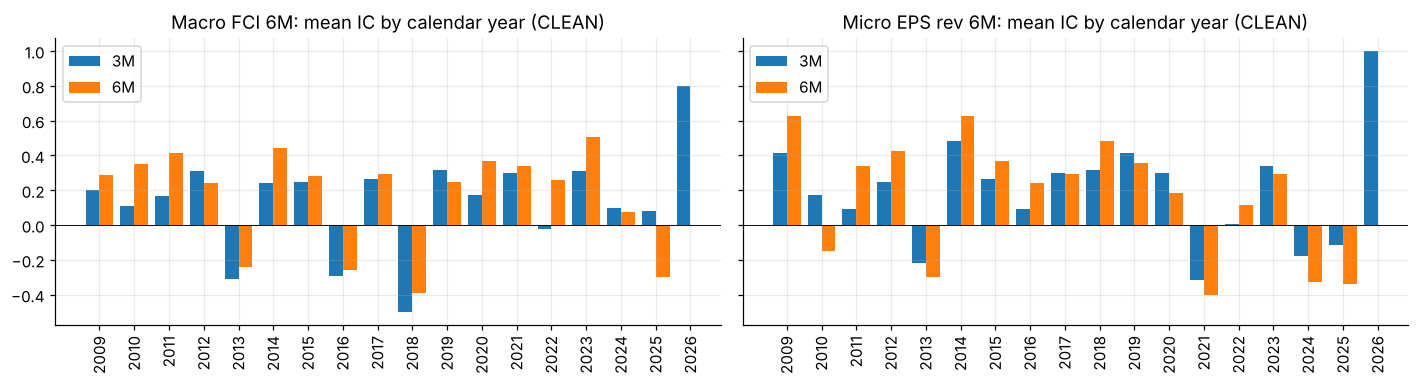

In [13]:
EPIS = {'GFC tail 2009-05..2009-12': ('2009-05', '2009-12'), 'Euro crisis 2011-07..2012-12': ('2011-07', '2012-12'),
        'China/oil 2015-08..2016-06': ('2015-08', '2016-06'), 'COVID 2020-02..2020-12': ('2020-02', '2020-12'),
        'Inflation/tightening 2022': ('2022-01', '2022-12')}
rows = []; YEARS = {}
for sname, (Zs, raw) in SIGS.items():
    for h in (3, 6):
        ic = ric(Zs, TGT[('usd', h)], CLEAN); v = win(ic, windows(CLEAN)['validation'])
        r = {'signal': sname, 'horizon': f'{h}M', 'full IC': ic.mean(), 'full median IC': ic.median(), 'share months > 0': (ic > 0).mean()}
        srt = ic.sort_values(ascending=False)
        for k in (1, 3, 6, 12):
            r[f'drop best {k}'] = srt.iloc[k:].mean()
        pos = ic[ic > 0].sort_values(ascending=False)
        r['top 10% months share of IC sum'] = ic.sort_values(ascending=False).iloc[:max(1, len(ic) // 10)].sum() / ic.sum()
        for e, (a, b) in EPIS.items():
            m = (ic.index >= pd.Period(a, 'M')) & (ic.index <= pd.Period(b, 'M')); r[f'ex {e}'] = ic[~m].mean()
        yr = ic.groupby(ic.index.year).mean(); YEARS[(sname, h)] = yr
        jk = {y: ic[ic.index.year != y].mean() for y in yr.index}
        r['year jackknife min'] = min(jk.values()); r['worst year to drop'] = min(jk, key=jk.get)
        r['year jackknife max'] = max(jk.values()); r['years with IC>0'] = f'{(yr > 0).sum()}/{len(yr)}'
        rows.append(r)
INFL = pd.DataFrame(rows).set_index(['signal', 'horizon'])
display(INFL.T)
INFL.to_csv(OUT/'month_influence.csv')
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, sname in zip(axs, SIGS):
    yr3, yr6 = YEARS[(sname, 3)], YEARS[(sname, 6)]
    xx = np.arange(len(yr3)); ax.bar(xx - .2, yr3.values, .4, label='3M'); ax.bar(xx + .2, yr6.reindex(yr3.index).values, .4, label='6M')
    ax.set_xticks(xx); ax.set_xticklabels(yr3.index, rotation=90); ax.axhline(0, c='k', lw=.6); ax.set_title(f'{sname}: mean IC by calendar year (CLEAN)'); ax.legend()
plt.tight_layout(); plt.savefig(CH/'ic_by_year.png', bbox_inches='tight'); plt.show()

### 6d. Specification sensitivity (not a search — nothing here is used to choose a specification)
All variants evaluated on **one common month set** (months where every variant is defined) so differences are attributable to the specification only.

In [14]:
def fci_var(lb=6, w=36, kind='expanding'):
    d = FCI - FCI.shift(lb)
    if kind == 'expanding': return d / d.expanding(w).std()
    if kind == 'rolling': return d / d.rolling(w).std()
    if kind == 'zscore': return (d - d.expanding(w).mean()) / d.expanding(w).std()
    return d
FV = {'BASE: 6M chg / expanding sd 36': fci_var(), 'expanding sd, burn-in 24 (identical once valid)': fci_var(w=24), 'expanding sd, burn-in 60 (identical once valid)': fci_var(w=60), 'rolling 36M sd': fci_var(kind='rolling'),
      'expanding z-score (60)': fci_var(w=60, kind='zscore'), 'unscaled change (mixed units!)': fci_var(kind='raw'),
      'lookback 3M': fci_var(3), 'lookback 9M': fci_var(9), 'lookback 12M': fci_var(12)}
EV = {'BASE: 6M % revision': EPS6, 'reporting lag 1M': EPS6.shift(1), 'reporting lag 2M': EPS6.shift(2), 'reporting lag 3M': EPS6.shift(3),
      'lookback 3M': EPS / EPS.shift(3) - 1, 'lookback 12M': EPS / EPS.shift(12) - 1, 'own-sd scaled': own_sd(EPS6), 'log revision': np.log(EPS / EPS.shift(6))}
def spec_table(V, base_key):
    Zv = {k: cs_z(v) for k, v in V.items()}
    ok = pd.concat([z.notna().all(axis=1) for z in Zv.values()], axis=1).all(axis=1)
    mm = IDX[ok.values]; mm = mm[mm >= CLEAN.min()]
    rows = []
    for k, z in Zv.items():
        r = {'variant': k}
        for tg, h in (('usd', 3), ('usd', 6), ('local', 3), ('local', 6), ('usd', 1), ('usd', 12)):
            ic = ric(z, TGT[(tg, h)], mm)
            r[f'{tg} {h}M full IC'] = ic.mean(); r[f'{tg} {h}M full t'] = hac_t(ic.values, h)[0]
            if (tg, h) in (('usd', 3), ('usd', 6)):
                v = win(ic, (VAL_START, mm.max())); r[f'{tg} {h}M val IC'] = v.mean(); r[f'{tg} {h}M val t'] = hac_t(v.values, h)[0]
        rows.append(r)
    return pd.DataFrame(rows).set_index('variant'), mm
SPF, mmF = spec_table(FV, 'BASE: 6M chg / expanding sd 36'); SPE, mmE = spec_table(EV, 'BASE: 6M % revision')
cols = ['usd 3M full IC', 'usd 3M full t', 'usd 3M val IC', 'usd 3M val t', 'usd 6M full IC', 'usd 6M full t', 'usd 6M val IC', 'usd 6M val t', 'local 3M full IC', 'local 6M full IC', 'usd 1M full IC', 'usd 12M full IC']
fmS = {c: ('{:+.2f}' if c.endswith(' t') else '{:+.3f}') for c in cols}
print(f'FCI variants - common months {mmF.min()}..{mmF.max()} ({len(mmF)})'); display(SPF[cols].style.format(fmS))
print(f'EPS variants - common months {mmE.min()}..{mmE.max()} ({len(mmE)})'); display(SPE[cols].style.format(fmS))
SPF.to_csv(OUT/'spec_sensitivity_fci.csv')
print('NOTE: the "36" in own_sd(…, 36) is a minimum-period burn-in of an EXPANDING sd, not a window - so 24/36/60 give identical values once all are defined. Earlier versions described it as a 36M window.'); SPE.to_csv(OUT/'spec_sensitivity_eps.csv')
# Pearson vs Spearman, and inference settings on the BASE series
rows = []
for sname, (Zs, raw) in SIGS.items():
    for h in (3, 6):
        ic = ric(Zs, TGT[('usd', h)], CLEAN)
        pear = pd.Series({t: np.corrcoef(Zs.loc[t], TGT[('usd', h)].loc[t])[0, 1] for t in ic.index})
        r = {'signal': sname, 'horizon': f'{h}M', 'Spearman IC': ic.mean(), 'Pearson IC': pear.mean()}
        for lg in (h, 2 * h, 3 * h): r[f'HAC t lags={lg}'] = hac_t(ic.values, lg)[0]
        for L in (h, 2 * h, 4 * h): lo, hi, p = mbb(ic.values, L); r[f'boot p L={L}'] = p; r[f'boot CI L={L}'] = f'[{lo:+.3f}, {hi:+.3f}]'
        rows.append(r)
INF = pd.DataFrame(rows).set_index(['signal', 'horizon']); display(INF)
INF.to_csv(OUT/'inference_sensitivity.csv')

FCI variants - common months 2011-05..2026-04 (180)


,usd 3M full IC,usd 3M full t,usd 3M val IC,usd 3M val t,usd 6M full IC,usd 6M full t,usd 6M val IC,usd 6M val t,local 3M full IC,local 6M full IC,usd 1M full IC,usd 12M full IC
variant,,,,,,,,,,,,
BASE: 6M chg / expanding sd 36,+0.106,+1.89,+0.127,+1.74,+0.162,+2.48,+0.173,+1.96,+0.093,+0.110,+0.049,+0.115
"expanding sd, burn-in 24 (identical once valid)",+0.106,+1.89,+0.127,+1.74,+0.162,+2.48,+0.173,+1.96,+0.093,+0.110,+0.049,+0.115
"expanding sd, burn-in 60 (identical once valid)",+0.106,+1.89,+0.127,+1.74,+0.162,+2.48,+0.173,+1.96,+0.093,+0.110,+0.049,+0.115
rolling 36M sd,+0.080,+1.61,+0.076,+1.25,+0.108,+1.79,+0.074,+1.00,+0.097,+0.080,+0.031,+0.058
expanding z-score (60),+0.110,+2.01,+0.110,+1.53,+0.150,+2.36,+0.153,+1.75,+0.095,+0.113,+0.068,+0.125
unscaled change (mixed units!),+0.081,+1.72,+0.122,+2.16,+0.116,+2.08,+0.123,+1.85,+0.086,+0.080,+0.026,+0.081
lookback 3M,+0.087,+1.77,+0.071,+1.07,+0.106,+2.17,+0.101,+1.62,+0.040,+0.080,+0.035,+0.138
lookback 9M,+0.121,+2.23,+0.122,+1.68,+0.146,+2.01,+0.154,+1.69,+0.085,+0.075,+0.038,+0.085
lookback 12M,+0.111,+1.99,+0.134,+1.94,+0.124,+1.77,+0.119,+1.40,+0.089,+0.030,+0.065,+0.045


EPS variants - common months 2009-05..2026-04 (204)


,usd 3M full IC,usd 3M full t,usd 3M val IC,usd 3M val t,usd 6M full IC,usd 6M full t,usd 6M val IC,usd 6M val t,local 3M full IC,local 6M full IC,usd 1M full IC,usd 12M full IC
variant,,,,,,,,,,,,
BASE: 6M % revision,+0.154,+2.82,+0.131,+1.70,+0.163,+2.36,+0.074,+0.78,+0.131,+0.102,+0.067,+0.162
reporting lag 1M,+0.163,+2.93,+0.132,+1.60,+0.148,+2.03,+0.034,+0.35,+0.124,+0.089,+0.064,+0.140
reporting lag 2M,+0.143,+2.68,+0.092,+1.25,+0.131,+1.80,+0.016,+0.18,+0.123,+0.063,+0.053,+0.139
reporting lag 3M,+0.128,+2.52,+0.058,+0.86,+0.125,+1.84,+0.039,+0.51,+0.108,+0.059,+0.064,+0.143
lookback 3M,+0.067,+1.33,+0.103,+1.60,+0.105,+1.81,+0.081,+1.02,+0.078,+0.081,+0.033,+0.130
lookback 12M,+0.103,+1.86,+0.046,+0.59,+0.133,+1.93,+0.043,+0.53,+0.092,+0.070,+0.061,+0.145
own-sd scaled,+0.185,+4.06,+0.174,+2.63,+0.226,+3.79,+0.151,+1.87,+0.144,+0.143,+0.113,+0.207
log revision,+0.154,+2.82,+0.131,+1.70,+0.163,+2.36,+0.074,+0.78,+0.131,+0.102,+0.067,+0.162


NOTE: the "36" in own_sd(…, 36) is a minimum-period burn-in of an EXPANDING sd, not a window - so 24/36/60 give identical values once all are defined. Earlier versions described it as a 36M window.


Spearman IC  Pearson IC  HAC t lags=3  HAC t lags=6  HAC t lags=9  boot p L=3       boot CI L=3  boot p L=6       boot CI L=6  boot p L=12      boot CI L=12  HAC t lags=12  HAC t lags=18  boot p L=24  \
signal           horizon                                                                                                                                                                                                            
Macro FCI 6M     3M             0.101       0.095         1.996         1.891         1.904       0.020  [+0.002, +0.195]       0.032  [-0.010, +0.198]        0.021  [-0.007, +0.195]            NaN            NaN          NaN   
                 6M             0.174       0.136           NaN         2.963           NaN         NaN               NaN       0.001  [+0.061, +0.277]        0.002  [+0.058, +0.299]          2.778          2.860        0.000   
Micro EPS rev 6M 3M             0.154       0.127         2.816         2.756         2.660       0.001  [+0.044, +0.252]       0.001  [+0.041, +0.260]        0.004  [+0.033, +0.254]            NaN            NaN          NaN   
                 6M             0.163       0.115           NaN         2.362           NaN         NaN               NaN       0.004  [+0.037, +0.289]        0.010  [+0.025, +0.300]          2.181          2.141        0.006   

                              boot CI L=24  
signal           horizon                    
Macro FCI 6M     3M                    NaN  
                 6M       [+0.076, +0.287]  
Micro EPS rev 6M 3M                    NaN  
                 6M       [+0.055, +0.313]

### 6e. Micro-specific: reporting lag, US field comparability, and fiscal-year roll effects
If a market's EPS field is a *fiscal-year* estimate rather than a blended 12M-forward one, it jumps when the fiscal year rolls, and a 6M "revision" then contains mechanical growth. Japan's fiscal year ends in March, the others mostly in December — a roll artefact would show up as calendar-month seasonality in Δlog EPS.

In [15]:
g = np.log(EPS / EPS.shift(1))
SEAS = g.groupby(g.index.month).mean().mul(100); SEAS.index.name = 'calendar month'
display(SEAS.style.format('{:+.2f}').background_gradient(axis=None, cmap='RdBu', vmin=-1.5, vmax=1.5))
seas_f = {}
for c in COUNTRIES:
    d = pd.DataFrame({'g': g[c], 'm': g.index.month}).dropna()
    mdl = sm.OLS(d.g.values, pd.get_dummies(d.m, drop_first=False).astype(float).values).fit()
    rest = sm.OLS(d.g.values, np.ones((len(d), 1))).fit()
    F = ((rest.ssr - mdl.ssr) / 11) / (mdl.ssr / (len(d) - 12)); from scipy.stats import f as fdist
    seas_f[c] = {'max-month mean Δlog EPS %': SEAS[c].max(), 'month': int(SEAS[c].idxmax()), 'median month %': SEAS[c].median(), 'F (11, n-12)': F, 'p': 1 - fdist.cdf(F, 11, len(d) - 12)}
SEASF = pd.DataFrame(seas_f).T; display(SEASF.style.format({'max-month mean Δlog EPS %': '{:+.2f}', 'median month %': '{:+.2f}', 'F (11, n-12)': '{:.2f}', 'p': '{:.3f}', 'month': '{:.0f}'}))
pxg = np.log(PX / PX.shift(1)); pseas = pxg.groupby(pxg.index.month).mean().mul(100)
print('Same seasonality test on the implied PRICE (a roll artefact in EPS would be offset by P/E, leaving price smooth):')
display(pseas.T.style.format('{:+.2f}'))
SEAS.to_csv(OUT/'eps_calendar_seasonality.csv'); SEASF.to_csv(OUT/'eps_seasonality_test.csv')
gg = EPS.pct_change()
CMP = pd.DataFrame({'EPS field': {c: SPEC[c]['eps'] for c in COUNTRIES}, 'monthly chg sd': gg.std(), 'autocorr(1)': gg.apply(lambda s: s.autocorr()),
                    'share months declining': (gg < 0).mean(), 'share |chg|<0.1%': (gg.abs() < 0.001).mean(), '6M revision sd': EPS6.std(),
                    'corr of 6M rev with US': EPS6.corr()['US']})
display(CMP.style.format({'monthly chg sd': '{:.4f}', 'autocorr(1)': '{:+.2f}', 'share months declining': '{:.0%}', 'share |chg|<0.1%': '{:.1%}', '6M revision sd': '{:.3f}', 'corr of 6M rev with US': '{:+.2f}'}))
CMP.to_csv(OUT/'eps_field_comparability.csv')

,US,Eurozone,UK,Switzerland,Japan
calendar month,,,,,
1,+0.11,+0.05,-0.78,-0.45,-0.08
2,+0.16,+0.13,-0.13,-0.81,-1.58
3,+0.50,-0.54,-0.17,-0.09,-0.07
4,+0.62,-0.04,-0.49,-0.62,-0.14
5,+0.95,+0.89,+1.05,+0.94,+0.87
6,+1.18,+0.32,+0.62,+0.28,+1.28
7,+1.02,+0.45,-0.07,+0.21,+1.96
8,+0.84,+1.04,+1.60,+0.73,+1.46
9,+0.88,+0.32,+0.69,+1.11,+0.83


,max-month mean Δlog EPS %,month,median month %,"F (11, n-12)",p
US,+1.18,6,+0.56,0.79,0.648
Eurozone,+1.04,8,+0.13,0.71,0.731
UK,+1.60,8,+0.02,1.05,0.401
Switzerland,+1.11,9,+0.24,1.85,0.047
Japan,+1.96,7,+0.16,0.67,0.770


Same seasonality test on the implied PRICE (a roll artefact in EPS would be offset by P/E, leaving price smooth):


,1,2,3,4,5,6,7,8,9,10,11,12
US,+0.19,-0.18,+0.76,+2.15,+0.45,+0.08,+2.37,+0.10,-0.62,+0.81,+2.00,+0.49
Eurozone,+0.58,+0.18,+0.02,+1.85,-0.84,-1.65,+1.62,-0.88,-0.31,+0.42,+1.05,+0.94
UK,-0.20,+0.49,-0.67,+2.12,-0.31,-1.28,+1.56,-0.85,-0.50,+0.21,+0.42,+1.75
Switzerland,+0.11,-0.02,+0.14,+1.12,-0.23,-1.27,+1.86,-0.02,-0.56,+0.13,+0.83,+0.48
Japan,+0.23,+0.53,-0.51,+1.80,+0.14,+0.24,+0.29,-1.08,-0.50,+0.06,+1.46,+1.38


,EPS field,monthly chg sd,autocorr(1),share months declining,share |chg|<0.1%,6M revision sd,corr of 6M rev with US
US,Monthly_EPS,0.0201,+0.65,20%,4.1%,0.085,+1.00
Eurozone,BEst EPS,0.0225,+0.73,32%,5.7%,0.097,+0.86
UK,BEst EPS,0.0290,+0.52,42%,4.1%,0.115,+0.78
Switzerland,BEst EPS,0.0199,+0.29,34%,3.7%,0.065,+0.61
Japan,BEst EPS,0.0463,+0.70,31%,4.9%,0.190,+0.80


### 6f. Selection-aware nulls on the CLEAN sample
**Block permutation:** country labels of the forward return are shuffled within h-month blocks (same shuffle for every signal), which destroys any cross-sectional link while keeping time-series structure. `p own` tests one pre-specified signal; `p best-of-family` asks how often the *best* of the v10 Macro+Micro variant family (19 signals) beats the observed value under the null — the relevant comparison because FCI 6M and EPS 6M were chosen from that family.
This corrects only for the immediate family. The project made ~25,500 cumulative selection decisions (v10 multiplicity ledger); no feasible null covers that history, so these p-values are **lower bounds** on the true selection-adjusted p.

In [16]:
FAM = {f'Macro|{k}': cs_z(v.reindex(IDX)) for k, v in ns10['MACRO_V'].items()} | {f'Micro|{k}': cs_z(v.reindex(IDX)) for k, v in ns10['MICRO_V'].items()}
famok = pd.concat([z.notna().all(axis=1) for z in FAM.values()], axis=1).all(axis=1)
FAMM = IDX[famok.values]; assert len(holes(FAMM)) == 0
def unit_ranks(A):
    r = rankdata(A, axis=-1); r = r - r.mean(-1, keepdims=True); n = np.sqrt((r**2).sum(-1, keepdims=True)); return np.where(n > 0, r / np.where(n > 0, n, 1), 0)
def perm_null(sigs, h, months, nperm=5000, seed=SEED):
    tg = TGT[('usd', h)].reindex(months); months = pd.PeriodIndex([m for m in months if tg.loc[m].notna().all()])
    RS = np.stack([unit_ranks(s.reindex(months).to_numpy(float)) for s in sigs.values()])     # K,T,5
    RY = unit_ranks(TGT[('usd', h)].reindex(months).to_numpy(float))                          # T,5
    T = len(months); blk = np.arange(T) // h; nb = blk.max() + 1
    rng = np.random.default_rng(seed); P = rng.permuted(np.tile(np.arange(5), (nperm, nb, 1)), axis=2)[:, blk, :]   # nperm,T,5
    RYp = np.take_along_axis(np.broadcast_to(RY, (nperm, T, 5)), P, axis=2)
    obs = np.einsum('ktc,tc->k', RS, RY) / T; null = np.einsum('ktc,ntc->nk', RS, RYp) / T
    return pd.Series(obs, index=list(sigs)), pd.DataFrame(null, columns=list(sigs)), months
rows = []
for h in (3, 6):
    for wl in ('validation', 'full'):
        mm = win(pd.Series(1, index=FAMM), (FAMM.min() if wl == 'full' else VAL_START, FAMM.max())).index
        obs, null, used = perm_null(FAM, h, mm); mx = null.max(axis=1)
        for k in ('Macro|fci chg 6M', 'Micro|eps rev 6M'):
            rows.append({'signal': k, 'horizon': f'{h}M', 'window': wl, 'months': f'{used.min()}..{used.max()} ({len(used)})', 'observed IC': obs[k],
                         'p own (add-one)': (1 + (null[k] >= obs[k]).sum()) / (1 + len(null)),
                         'null 95th pct (own)': null[k].quantile(.95), 'null 95th pct (best of 19)': mx.quantile(.95),
                         'p best-of-19 (add-one)': (1 + (mx >= obs[k]).sum()) / (1 + len(mx))})
NULL = pd.DataFrame(rows).set_index(['signal', 'horizon', 'window'])
display(NULL.style.format({'observed IC': '{:+.3f}', 'p own (add-one)': '{:.4f}', 'null 95th pct (own)': '{:+.3f}', 'null 95th pct (best of 19)': '{:+.3f}', 'p best-of-19 (add-one)': '{:.4f}'}))
NULL.to_csv(OUT/'selection_nulls_clean.csv')
print(f'Family sample starts {FAMM.min()} (the 60M expanding z-score in "fci level z" needs history); no holes.')

,,,months,observed IC,p own (add-one),null 95th pct (own),null 95th pct (best of 19),p best-of-19 (add-one)
signal,horizon,window,,,,,,
Macro|fci chg 6M,3M,validation,2017-07..2026-01 (103),+0.127,0.0150,+0.095,+0.164,0.1950
Micro|eps rev 6M,3M,validation,2017-07..2026-01 (103),+0.131,0.0200,+0.105,+0.164,0.1756
Macro|fci chg 6M,3M,full,2010-11..2026-01 (183),+0.097,0.0198,+0.078,+0.130,0.2062
Micro|eps rev 6M,3M,full,2010-11..2026-01 (183),+0.145,0.0026,+0.083,+0.130,0.0230
Macro|fci chg 6M,6M,validation,2017-07..2025-10 (100),+0.173,0.0178,+0.135,+0.216,0.1598
Micro|eps rev 6M,6M,validation,2017-07..2025-10 (100),+0.074,0.1952,+0.144,+0.216,0.7862
Macro|fci chg 6M,6M,full,2010-11..2025-10 (180),+0.152,0.0082,+0.101,+0.158,0.0622
Micro|eps rev 6M,6M,full,2010-11..2025-10 (180),+0.161,0.0062,+0.104,+0.158,0.0444


Family sample starts 2010-11 (the 60M expanding z-score in "fci level z" needs history); no holes.


### 6g. Do HAC t and the block bootstrap have the right size here?
The validation window has ~100 overlapping monthly ICs (≈17 independent 6M periods). Newey-West is known to over-reject in samples this small with strong overlap. Measured directly: keep the **actual** signals, replace returns with months drawn at random (with replacement) from the actual 1M relative-return history — this keeps fat tails and the cross-market covariance but has **no true predictability** — rebuild h-month targets, and record how often each test rejects at a nominal 5 %.

In [17]:
R1 = PX_USD.pct_change().sub(PX_USD.pct_change().mean(axis=1), axis=0).reindex(IDX)
R1v = R1.dropna().to_numpy()
def size_sim(Zs, h, months, nsim=1000, seed=11, pure=True):
    rng = np.random.default_rng(seed); T = len(IDX); res = []; means = []
    pool = R1v - R1v.mean(0, keepdims=True) if pure else R1v      # pure: remove each market's average drift -> zero expected IC
    ZsA = unit_ranks(Zs.reindex(IDX).to_numpy(float)); valid_s = Zs.reindex(IDX).notna().all(axis=1).to_numpy()
    pos = np.array([IDX.get_loc(m) for m in months if IDX.get_loc(m) + h < T])
    for i in range(nsim):
        r = pool[rng.integers(0, len(pool), T)]                     # T x 5 fake monthly relative returns
        lr = np.log1p(r); cum = np.vstack([np.zeros((1, 5)), np.cumsum(lr, 0)])
        fwdh = np.expm1(cum[pos + 1 + h] - cum[pos + 1])             # return from t+1..t+h (month t+1 onward)
        fwdh = fwdh - fwdh.mean(1, keepdims=True)
        ic = (ZsA[pos] * unit_ranks(fwdh)).sum(1)
        t, _ = hac_t(ic, h); lo, hi, p = mbb(ic, 2 * h, n=500, seed=i)
        res.append((t, p)); means.append(ic.mean())
    res = np.array(res)
    return {'HAC t>1.645 (1-sided 5%)': (res[:, 0] > 1.645).mean(), '|HAC t|>1.96 (2-sided 5%)': (np.abs(res[:, 0]) > 1.96).mean(),
            'boot p<0.05 (1-sided)': (res[:, 1] < 0.05).mean(), 'HAC t 95th pct under null': np.percentile(res[:, 0], 95),
            'mean-IC 95th pct under null': np.percentile(means, 95), 'mean IC under null (avg)': np.mean(means)}
rows = []
for sname, (Zs, raw) in SIGS.items():
    for h in (3, 6):
        for wl, mm in (('validation', VALM), ('full', CLEAN)):
            for pure in (True, False):
                rows.append({'signal': sname, 'horizon': f'{h}M', 'window': wl, 'null': 'pure (drift removed)' if pure else 'drift kept',
                             'n months': len(mm), **size_sim(Zs, h, mm, pure=pure)})
SIZE = pd.DataFrame(rows).set_index(['signal', 'horizon', 'window', 'null'])
display(SIZE.style.format({c: '{:.1%}' for c in SIZE.columns if c.startswith(('HAC t>', '|HAC', 'boot'))} | {c: '{:+.3f}' for c in SIZE.columns if 'mean' in c} | {'HAC t 95th pct under null': '{:.2f}'}))
SIZE.to_csv(OUT/'test_size_simulation.csv')
print('Nominal size is 5%. Rejection rates well above 5% mean the reported t-stats/p-values overstate significance;')
print('the "HAC t 95th pct under null" column is the empirical one-sided 5% critical value to use instead of 1.645.')
print('"drift kept" leaves each market its historical average relative return: a signal that PERSISTENTLY ranks a market high then earns IC with no timing skill.')

Nominal size is 5%. Rejection rates well above 5% mean the reported t-stats/p-values overstate significance;
the "HAC t 95th pct under null" column is the empirical one-sided 5% critical value to use instead of 1.645.
"drift kept" leaves each market its historical average relative return: a signal that PERSISTENTLY ranks a market high then earns IC with no timing skill.


### 6h. Timing skill or a static country tilt?
The US outperformed the other four markets for most of 2009–2026. A signal that simply keeps the US near the top earns positive IC without any timing ability.
Decomposition: (i) **timing IC** — the target with each market's full-sample average relative return removed (a diagnostic; it uses the whole sample, so it is not tradable); (ii) **static-tilt IC** — a constant signal equal to each market's average signal score.

In [18]:
rows = []
for sname, (Zs, raw) in SIGS.items():
    for h in (3, 6):
        Y = TGT[('usd', h)]
        for wl, mm in (('full', CLEAN), ('validation', VALM)):
            Ym = Y.reindex(mm); Yt = Ym - Ym.mean()
            tilt = Zs.reindex(mm).mean(); Zst = pd.DataFrame([tilt.values] * len(mm), index=mm, columns=COUNTRIES)
            raw_ic = ric(Zs, Y, mm); tim = ric(Zs, Yt.reindex(IDX), mm); st = ric(Zst.reindex(IDX), Y, mm)
            rows.append({'signal': sname, 'horizon': f'{h}M', 'window': wl, 'raw IC': raw_ic.mean(), 'raw t': hac_t(raw_ic.values, h)[0],
                         'timing IC (drift removed)': tim.mean(), 'timing t': hac_t(tim.values, h)[0], 'static-tilt IC': st.mean(),
                         'avg signal z: ' + ' / '.join(c[:2] for c in COUNTRIES): ' / '.join(f'{v:+.2f}' for v in tilt.values),
                         'avg fwd rel. return %/yr: ' + ' / '.join(c[:2] for c in COUNTRIES): ' / '.join(f'{v*1200/h:+.1f}' for v in Ym.mean().values)})
TILT = pd.DataFrame(rows).set_index(['signal', 'horizon', 'window'])
display(TILT.style.format({c: '{:+.3f}' for c in TILT.columns if 'IC' in c} | {c: '{:+.2f}' for c in TILT.columns if c.endswith(' t')}))
TILT.to_csv(OUT/'timing_vs_static_tilt.csv')

## 7. Closing Valuation and Technical
Four constructions are documented here. **No new selection** is made: the two exploratory signals were identified in v10 partly by looking at the validation window, so the validation window can no longer serve as independent evidence for them. They are re-evaluated on hole-free months for documentation only.

In [19]:
ERPC = ns10['VAL_V']['ERP vs credit (E/P-2Y-OAS)']; TRR2 = ns10['TECH_V']['PATH trend quality R2 12M']
PEPEER = ns10['VAL_V']['P/E vs peers (cheap+)']; LOWV = ns10['TECH_V']['PATH low realised vol 12M']
CLOSE = {'Valuation | ERP vs credit (E/P − 2Y − OAS)': ERPC, 'Technical | trend quality R² 12M': TRR2,
         'Valuation | P/E vs peers (cheap+)': PEPEER, 'Technical | PATH low realised vol 12M': LOWV}
rows = []
for nm, raw in CLOSE.items():
    z = cs_z(raw.reindex(IDX)); mm = IDX[(z.notna().all(axis=1) & both).values]
    assert len(holes(mm)) == 0
    r = {'signal': nm, 'months': f'{mm.min()}..{mm.max()}'}
    for h in (3, 6):
        ic = ric(z, TGT[('usd', h)], mm)
        for wl, w in (('disc', (mm.min(), EMB_END)), ('val', (VAL_START, mm.max()))):
            x = win(ic, w); r[f'{wl} {h}M IC'] = x.mean(); r[f'{wl} {h}M t'] = hac_t(x.values, h)[0]
    for leg in ('multiple', 'earnings'):
        ic = ric(z, TGT[(leg, 3)], mm)
        r[f'disc 3M {leg}-leg IC'] = win(ic, (mm.min(), EMB_END)).mean(); r[f'val 3M {leg}-leg IC'] = win(ic, (VAL_START, mm.max())).mean()
    ic = ric(z, TGT[('usd', 3)], mm); inc = ric((ZF + ZE + z) / 3, TGT[('usd', 3)], mm) - ric((ZF + ZE) / 2, TGT[('usd', 3)], mm)
    r['val ΔIC vs FCI+EPS'] = win(inc, (VAL_START, mm.max())).mean(); r['val ΔIC t'] = hac_t(win(inc, (VAL_START, mm.max())).values, 3)[0]
    rows.append(r)
CLS = pd.DataFrame(rows).set_index('signal')
display(CLS.T)
CLS.to_csv(OUT/'valuation_technical_closure_stats.csv')
# Is low vol simply a beta bet? IC split by the direction of the equal-weight market over the next 3M
mkt3 = (PX_USD.shift(-3) / PX_USD - 1).mean(axis=1)
zlv = cs_z(LOWV.reindex(IDX)); iclv = ric(zlv, TGT[('usd', 3)], CLEAN)
up = mkt3.reindex(iclv.index) > 0
print(f'PATH low-vol IC when the 5-market average RISES over the next 3M: {iclv[up].mean():+.3f} ({up.sum()} months); when it FALLS: {iclv[~up].mean():+.3f} ({(~up).sum()} months)')
zpp = cs_z(PEPEER.reindex(IDX)); stick = zpp.apply(lambda s: s.autocorr(12))
print('P/E-vs-peers 12-month autocorrelation of the cross-sectional z-score (persistence of "cheap"):', stick.round(2).to_dict())
print('Who is persistently "cheap"? share of months each market ranks cheapest or 2nd cheapest:', (zpp.rank(axis=1, ascending=False) <= 2).mean().round(2).to_dict())
oas_units = OAS.describe().loc[['mean', 'min', 'max']].T; print('\nCredit spreads used in ERP-vs-credit (units/levels differ by market):'); display(oas_units)

signal,Valuation | ERP vs credit (E/P − 2Y − OAS),Technical | trend quality R² 12M,Valuation | P/E vs peers (cheap+),Technical | PATH low realised vol 12M
months,2010-11..2026-04,2009-05..2026-04,2010-11..2026-04,2009-05..2026-04
disc 3M IC,0.100,0.003,0.168,0.071
disc 3M t,1.147,0.056,1.733,1.203
val 3M IC,-0.017,0.106,-0.108,-0.066
val 3M t,-0.249,1.453,-1.573,-1.012
disc 6M IC,0.199,0.047,0.249,0.121
disc 6M t,1.896,0.550,1.716,1.538
val 6M IC,0.033,0.176,-0.112,-0.029
val 6M t,0.313,2.548,-1.245,-0.280
disc 3M multiple-leg IC,0.261,-0.088,0.077,0.051


PATH low-vol IC when the 5-market average RISES over the next 3M: -0.009 (135 months); when it FALLS: -0.020 (66 months)
P/E-vs-peers 12-month autocorrelation of the cross-sectional z-score (persistence of "cheap"): {'US': 0.69, 'Eurozone': 0.3, 'UK': 0.88, 'Switzerland': -0.03, 'Japan': 0.82}
Who is persistently "cheap"? share of months each market ranks cheapest or 2nd cheapest: {'US': 0.1, 'Eurozone': 0.24, 'UK': 0.4, 'Switzerland': 0.17, 'Japan': 0.61}

Credit spreads used in ERP-vs-credit (units/levels differ by market):


,mean,min,max
US,4.852,2.380,18.330
Eurozone,1.421,0.440,4.610
UK,1.734,0.740,5.910
Switzerland,1.421,0.440,4.610
Japan,0.419,0.130,1.010


In [20]:
DOC = pd.DataFrame([
 {'signal': 'ERP vs credit (E/P − 2Y − OAS), own-history z (60M)', 'status': 'EXPLORATORY — not promoted',
  'rationale': 'Equities priced cheaply relative to BOTH the risk-free rate and credit compensation should re-rate; a relative equity-risk-premium.',
  'exact construction': 'z_own(100/PE − 2Y yield − credit OAS, expanding 60M); higher = cheaper; cross-sectional z each month.',
  'discovery / validation status': f"disc 3M IC {CLS.iloc[0]['disc 3M IC']:+.3f} (t {CLS.iloc[0]['disc 3M t']:+.2f}); predicts the MULTIPLE leg in discovery ({CLS.iloc[0]['disc 3M multiple-leg IC']:+.3f}) but the earnings leg offsets it; val 3M {CLS.iloc[0]['val 3M IC']:+.3f}. Identified after the validation window had been seen.",
  'data needed to promote': 'A fresh out-of-sample period after 2026-04 (forward observation); a consistent credit index per market (US uses a HIGH-YIELD index, others investment grade; CH reuses the EZ index); dividend yields to test on total returns.',
  'why not promotable now': 'Total-return evidence is weak in discovery and the validation window is no longer independent for it. Promoting it would be selection on the validation set.'},
 {'signal': 'Trend quality R² (12M, log implied price on time)', 'status': 'EXPLORATORY — not promoted',
  'rationale': 'Smooth, low-noise trends signal gradual information diffusion and tend to persist; a path property that EPS cannot reproduce.',
  'exact construction': 'R² of OLS of log local implied price on a linear time trend over the last 12 month-ends; cross-sectional z.',
  'discovery / validation status': f"disc 3M IC {CLS.iloc[1]['disc 3M IC']:+.3f} — would NOT have been chosen by the discovery-only rule; val 3M {CLS.iloc[1]['val 3M IC']:+.3f} (t {CLS.iloc[1]['val 3M t']:+.2f}). Earnings-free version retained most of the IC in v10 (R² on earnings block 2.3%).",
  'data needed to promote': 'Fresh out-of-sample months; a pre-registered SIGNED version (sign(slope) × R²) — the current construction is unsigned and scores a smooth DOWN-trend as attractive, which has no economic rationale.',
  'why not promotable now': 'Its only supporting evidence is the window used to notice it; it failed discovery; the construction itself is mis-specified (unsigned). Any repair must be pre-registered and tested on new data.'},
 {'signal': 'P/E vs peers (cheap+)', 'status': 'REJECTED',
  'rationale': 'Relative cheapness mean-reverts across markets.',
  'exact construction': '−z_own(PE / cross-market mean PE, 60M); cross-sectional z.',
  'discovery / validation status': f"disc 3M {CLS.iloc[2]['disc 3M IC']:+.3f}, val 3M {CLS.iloc[2]['val 3M IC']:+.3f} (t {CLS.iloc[2]['val 3M t']:+.2f}); val ΔIC when added to FCI+EPS {CLS.iloc[2]['val ΔIC vs FCI+EPS']:+.3f} (t {CLS.iloc[2]['val ΔIC t']:+.2f}).",
  'data needed to promote': 'Sector-neutral P/E (country P/E gaps are dominated by sector mix); longer horizons (>12M) where valuation effects are usually measured.',
  'why not promotable now': 'Negative in validation and harmful incrementally. Mechanism: cheap markets get multiple expansion but lower earnings (legs correlate −0.77); and "cheap" is extremely persistent — the same markets stay cheap for years, so a 3–6M horizon sees no reversion.'},
 {'signal': 'PATH low realised volatility 12M', 'status': 'REJECTED',
  'rationale': 'Low-volatility anomaly: lower-risk assets earn better risk-adjusted returns.',
  'exact construction': '−std(12 monthly local implied-price returns); cross-sectional z.',
  'discovery / validation status': f"disc 3M {CLS.iloc[3]['disc 3M IC']:+.3f}, val 3M {CLS.iloc[3]['val 3M IC']:+.3f} (t {CLS.iloc[3]['val 3M t']:+.2f}).",
  'data needed to promote': 'A beta-neutral formulation, total returns, a larger cross-section.',
  'why not promotable now': f"Sign flips from discovery to validation, and the flip is NOT explained by market direction (IC {iclv[up].mean():+.3f} in rising and {iclv[~up].mean():+.3f} in falling 3M markets) - an initial beta-bet hypothesis was tested and refuted. No identified mechanism; the stock-level low-vol effect (leverage constraints) has no clear country-level analogue in a 5-market cross-section."},
]).set_index('signal')
display(DOC)
DOC.to_csv(OUT/'valuation_technical_closure.csv')
audit('valuation', 'Valuation pillar predictive evidence', 'VERIFIED (negative)', 'P/E vs peers negative in validation and incrementally; ERP-vs-credit exploratory only',
      'Valuation stays in the diagnostic scorecard (context), NOT in the predictive score.')
audit('technical', 'Technical pillar predictive evidence', 'VERIFIED (negative) / UNRESOLVED', 'PATH low vol rejected (sign flip, not explained by market direction); trend R² failed discovery and is unsigned',
      'Technical stays in the diagnostic scorecard only. Trend R² requires a pre-registered signed version on new data.')

,status,rationale,exact construction,discovery / validation status,data needed to promote,why not promotable now
signal,,,,,,
"ERP vs credit (E/P − 2Y − OAS), own-history z (60M)",EXPLORATORY — not promoted,Equities priced cheaply relative to BOTH the r...,"z_own(100/PE − 2Y yield − credit OAS, expandin...",disc 3M IC +0.100 (t +1.15); predicts the MULT...,A fresh out-of-sample period after 2026-04 (fo...,Total-return evidence is weak in discovery and...
"Trend quality R² (12M, log implied price on time)",EXPLORATORY — not promoted,"Smooth, low-noise trends signal gradual inform...",R² of OLS of log local implied price on a line...,disc 3M IC +0.003 — would NOT have been chosen...,Fresh out-of-sample months; a pre-registered S...,Its only supporting evidence is the window use...
P/E vs peers (cheap+),REJECTED,Relative cheapness mean-reverts across markets.,"−z_own(PE / cross-market mean PE, 60M); cross-...","disc 3M +0.168, val 3M -0.108 (t -1.57); val Δ...",Sector-neutral P/E (country P/E gaps are domin...,Negative in validation and harmful incremental...
PATH low realised volatility 12M,REJECTED,Low-volatility anomaly: lower-risk assets earn...,−std(12 monthly local implied-price returns); ...,"disc 3M +0.071, val 3M -0.066 (t -1.01).","A beta-neutral formulation, total returns, a l...","Sign flips from discovery to validation, and t..."


## 8. Methodology audit
### 8a. Point-in-time: does any signal at month t change if data after t is deleted?
Truncate the raw panel at month m, rebuild every signal from scratch, and compare the value at m with the full-data value at m. Any difference = look-ahead.

In [21]:
def build_signals(PEx, EPSx, FCIx):
    return {'FCI 6M': cs_z(own_sd(FCIx - FCIx.shift(6))), 'EPS 6M': cs_z(EPSx / EPSx.shift(6) - 1),
            'P/E vs peers': cs_z(-z_own(PEx.div(PEx.mean(axis=1), axis=0))), 'low vol': cs_z(-(PEx * EPSx).pct_change().rolling(12).std()),
            'trend R2': cs_z(ns10['trend_r2'](PEx * EPSx, 12))}
FULLSIG = build_signals(PE, EPS, FCI); worst = 0.0; tested = []
for m in [pd.Period(x, 'M') for x in ('2012-06', '2016-12', '2020-03', '2023-09', '2026-01')]:
    cut = IDX <= m; T_ = build_signals(PE[cut], EPS[cut], FCI[cut])
    for k in FULLSIG:
        worst = max(worst, float((T_[k].loc[m] - FULLSIG[k].loc[m]).abs().max())); tested.append((str(m), k))
print(f'{len(tested)} (month, signal) truncation tests; max |difference| = {worst:.1e}')
audit('point-in-time', 'Look-ahead in signal construction', 'VERIFIED' if worst < 1e-12 else 'FAILED',
      f'Truncation test on 5 dates x 5 signals: max diff {worst:.0e}', 'No signal uses data after its formation month.')
audit('point-in-time', 'Consensus EPS / P/E are point-in-time snapshots (not restated)', 'UNRESOLVED',
      'No vendor metadata in the workbooks; cannot be tested with the data provided',
      'If history were restated, EPS-revision ICs would be biased upward. 1-3M reporting-lag tests (§6d) bound the timing risk only.')

25 (month, signal) truncation tests; max |difference| = 0.0e+00


### 8b. Forward returns: independent recomputation

In [22]:
rng = np.random.default_rng(3); errs = []
for _ in range(200):
    h = int(rng.choice([3, 6])); i = int(rng.integers(0, len(IDX) - h)); c = COUNTRIES[int(rng.integers(0, 5))]
    raw_r = {k: PX_USD[k].iloc[i + h] / PX_USD[k].iloc[i] - 1 for k in COUNTRIES}
    errs.append(abs((raw_r[c] - np.mean(list(raw_r.values()))) - TGT[('usd', h)][c].iloc[i]))
print(f'200 random (month, market, horizon) cells recomputed by hand: max |error| = {max(errs):.1e}')
print(f"Signal at month-end t; target = USD implied-price return from month-end t to month-end t+h, minus the 5-market mean. "
      f"Last 3M target month {TGT[('usd',3)].dropna().index.max()}, last 6M {TGT[('usd',6)].dropna().index.max()}.")
audit('target', '3M/6M forward relative returns', 'VERIFIED', f'200 random cells recomputed; max error {max(errs):.0e}; no overlap with the formation month',
      'Correct. Overlapping monthly observations -> handled by HAC/bootstrap (whose size is checked in §6g).')

200 random (month, market, horizon) cells recomputed by hand: max |error| = 0.0e+00
Signal at month-end t; target = USD implied-price return from month-end t to month-end t+h, minus the 5-market mean. Last 3M target month 2026-01, last 6M 2025-10.


### 8c. Price return vs total return — how large a dividend gap would overturn the result?
Dividends are not in the data, so they cannot be added. Instead: add a constant annual carry of ±δ to ONE market's forward return at a time (re-demeaned) and see how far the IC moves. Persistent dividend-yield gaps between DM indices are typically a few percent per year (general knowledge, not used in any computation).

In [23]:
rows = []
for sname, (Zs, raw) in SIGS.items():
    for h in (3, 6):
        base_full = ric(Zs, TGT[('usd', h)], CLEAN).mean(); base_val = ric(Zs, TGT[('usd', h)], VALM).mean()
        r = {'signal': sname, 'horizon': f'{h}M', 'base full IC': base_full, 'base val IC': base_val}
        for d in (0.02, 0.04):
            res = []
            for c in COUNTRIES:
                for sgn in (1, -1):
                    y = (PX_USD.shift(-h) / PX_USD - 1); y = y.copy(); y[c] = y[c] + sgn * d * h / 12
                    y = y.sub(y.mean(axis=1), axis=0); res.append((ric(Zs, y, CLEAN).mean(), ric(Zs, y, VALM).mean()))
            res = np.array(res); r[f'min full IC, |δ|={d:.0%}'] = res[:, 0].min(); r[f'min val IC, |δ|={d:.0%}'] = res[:, 1].min()
        rows.append(r)
CARRY = pd.DataFrame(rows).set_index(['signal', 'horizon']); display(CARRY.style.format('{:+.3f}'))
CARRY.to_csv(OUT/'total_return_carry_stress.csv')
audit('target', 'Price return instead of total return', 'UNRESOLVED (bounded)',
      'No dividend data. Carry stress of ±2-4% p.a. on any single market moves the IC by the amounts shown in total_return_carry_stress.csv',
      'High-yield markets (UK) are understated in both target and backtest returns; rank ICs are only mildly affected because carry is small vs 3-6M return dispersion.')

### 8d. Remaining methodology items

In [24]:
lag1 = cs_z(own_sd(FCI - FCI.shift(6)).shift(1))
print(f"FCI 6M lagged 1M (timing-robustness): full 3M IC {ric(lag1, TGT[('usd',3)], CLEAN).mean():+.3f} vs {ric(ZF, TGT[('usd',3)], CLEAN).mean():+.3f} unlagged")
print('Core-field missing values inside the panel:', int(pd.concat([PE, EPS, FCI, FX, Y2, OAS], axis=1).isna().sum().sum()))
loc_cmp = pd.DataFrame({'USD 3M full': [SPF.iloc[0]['usd 3M full IC'], SPE.iloc[0]['usd 3M full IC']], 'local 3M full': [SPF.iloc[0]['local 3M full IC'], SPE.iloc[0]['local 3M full IC']],
                        'USD 6M full': [SPF.iloc[0]['usd 6M full IC'], SPE.iloc[0]['usd 6M full IC']], 'local 6M full': [SPF.iloc[0]['local 6M full IC'], SPE.iloc[0]['local 6M full IC']]},
                       index=['FCI 6M', 'EPS 6M']); display(loc_cmp.style.format('{:+.3f}'))
audit('target', 'USD vs local-currency returns', 'VERIFIED', 'Both computed; see table and spec_sensitivity_*.csv', 'Conclusions do not depend on the currency choice if the two columns agree in sign and rough size.')
audit('price', 'Implied price = BEst P/E x EPS', 'VERIFIED', 'Accounting identity; v4 matched S&P 500 monthly returns to ~0.04pp', 'Genuine price-return index (no dividends). Valid for returns; EPS revisions read from the same field.')
audit('price', 'US EPS field (Monthly_EPS) vs BEst EPS elsewhere', 'PROVISIONAL', 'Identity reproduces SPX, so it is consistent with the US P/E; its revision dynamics differ (eps_field_comparability.csv)',
      'US EPS-revision readings may not be strictly comparable; EPS ex-US LOO is reported.')
audit('data', 'Switzerland FCI and credit spread are euro-area series', 'VERIFIED', 'GSEAFCI and LECPOAS reused; high correlation with EZ shown in §6b',
      'Effectively 4 independent FCI readings; CH macro reading is not Swiss-specific.')
audit('data', 'Credit spreads mix HY (US) and IG (others)', 'VERIFIED', 'LF98OAS is US high yield; LECPOAS/LC61OAS/LJC1OAS are IG corporate',
      'Credit-based signals are not like-for-like across markets; own-history z-scoring only partly offsets this.')
audit('inference', 'HAC t with lags = h, block bootstrap L = 2h', 'see size table', 'Empirical size measured in §6g under a no-predictability null',
      'Where empirical size exceeds 5%, nominal p-values overstate significance; use the empirical critical values.')
audit('inference', 'Multiple testing / selection', 'PARTIAL', 'Best-of-19 family null computed (§6f); ~25,500 cumulative decisions cannot be fully corrected',
      'Family-adjusted p-values are lower bounds. No signal can be called statistically significant after full selection accounting.')

FCI 6M lagged 1M (timing-robustness): full 3M IC +0.120 vs +0.101 unlagged
Core-field missing values inside the panel: 0


,USD 3M full,local 3M full,USD 6M full,local 6M full
FCI 6M,+0.106,+0.093,+0.162,+0.110
EPS 6M,+0.154,+0.131,+0.163,+0.102


## 9. Verdict — each retained candidate against explicit criteria
Criteria fixed before reading the outcome. Critical values come from the **pure no-predictability simulation** (§6g), not the textbook 1.645. Criteria 5 and 6 are the two new adversarial checks from this audit.

In [25]:
rows = []
for sname, key in (('Macro FCI 6M', 'Macro|fci chg 6M'), ('Micro EPS rev 6M', 'Micro|eps rev 6M')):
    for h in (3, 6):
        H = f'{h}M'; c = CANON.loc[(sname, 'CLEAN (2-signal, no holes)', H)]
        cv = SIZE.loc[(sname, H, 'validation', 'pure (drift removed)'), 'HAC t 95th pct under null']
        lo = LOOT.loc[(sname, H, 'validation')]; tl = TILT.loc[(sname, H, 'validation')]
        crit = {
            '1 validation IC > 0': c['validation IC'] > 0,
            '2 validation HAC t > empirical 5% cv': c['validation t'] > cv,
            '3 own block-permutation p < 0.05 (val)': NULL.loc[(key, H, 'validation'), 'p own (add-one)'] < 0.05,
            '4 best-of-19 family p < 0.05 (val)': NULL.loc[(key, H, 'validation'), 'p best-of-19 (add-one)'] < 0.05,
            '5 timing IC (drift removed) t > empirical cv (val)': tl['timing t'] > cv,
            '6 every leave-one-out validation IC > 0': all(lo[f'ex-{k} IC'] > 0 for k in COUNTRIES),
            '7 full IC > 0 after dropping best 12 months': INFL.loc[(sname, H), 'drop best 12'] > 0,
            '8 validation IC > 0 under ±4% p.a. carry stress': CARRY.loc[(sname, H), 'min val IC, |δ|=4%'] > 0,
        }
        core = crit['1 validation IC > 0'] and crit['6 every leave-one-out validation IC > 0'] and crit['7 full IC > 0 after dropping best 12 months']
        status = 'VALIDATED' if all(crit.values()) else ('PROVISIONAL' if core and (crit['3 own block-permutation p < 0.05 (val)'] or crit['2 validation HAC t > empirical 5% cv']) else 'WEAK / NOT SUPPORTED')
        rows.append({'signal': sname, 'horizon': H, 'val IC': c['validation IC'], 'val t': c['validation t'], 'empirical cv': cv,
                     'timing t (val)': tl['timing t'], **crit, 'criteria passed': f'{sum(crit.values())}/8', 'STATUS': status})
VERD = pd.DataFrame(rows).set_index(['signal', 'horizon'])
display(VERD.T)
VERD.to_csv(OUT/'verdict_retained_candidates.csv')
FINAL = pd.DataFrame([
 {'pillar': 'Macro', 'signal': 'FCI 6M easing (own-sd scaled)', 'v10 status': 'PROVISIONAL (strongest)', 'v11 status': '/'.join(VERD.loc['Macro FCI 6M', 'STATUS']),
  'reason': 'v10 validation t 2.49 depended on 27 censored stress months; clean t 1.74 (3M) / 1.96 (6M); survives drift removal better than EPS; 3M depends on the US (ex-US t 0.72), 6M does not (ex-US t 1.92); fails family-selection null'},
 {'pillar': 'Micro', 'signal': 'EPS revision 6M', 'v10 status': 'PROVISIONAL', 'v11 status': '/'.join(VERD.loc['Micro EPS rev 6M', 'STATUS']),
  'reason': 'Clean 3M validation IC +0.131 but most of it is a static US/Japan tilt: timing IC +0.072 (t 0.99) at 3M and +0.012 at 6M; UK is the largest single contributor; fails family-selection null'},
 {'pillar': 'Valuation', 'signal': 'P/E vs peers / ERP vs credit', 'v10 status': 'REJECTED / exploratory', 'v11 status': 'REJECTED / EXPLORATORY',
  'reason': 'P/E vs peers negative in validation and harmful incrementally (ΔIC t −3.3 on clean months); ERP-vs-credit cannot be validated on data already seen'},
 {'pillar': 'Technical', 'signal': 'PATH low vol / trend-quality R²', 'v10 status': 'REJECTED / exploratory', 'v11 status': 'REJECTED / EXPLORATORY',
  'reason': 'Low vol flips sign; trend R² failed discovery, is unsigned, and its supporting evidence is the window used to notice it'},
]).set_index('pillar')
display(FINAL); FINAL.to_csv(OUT/'final_status_v11.csv')

signal                                             Macro FCI 6M              Micro EPS rev 6M                      
horizon                                                      3M           6M               3M                    6M
val IC                                                    0.127        0.173            0.131                 0.074
val t                                                     1.736        1.961            1.698                 0.783
empirical cv                                              2.031        2.032            1.803                 1.982
timing t (val)                                            1.498        1.909            0.985                 0.127
1 validation IC > 0                                        True         True             True                  True
2 validation HAC t > empirical 5% cv                      False        False            False                 False
3 own block-permutation p < 0.05 (val)                     True         True             True                 False
4 best-of-19 family p < 0.05 (val)                        False        False            False                 False
5 timing IC (drift removed) t > empirical cv (val)        False        False            False                 False
6 every leave-one-out validation IC > 0                    True         True             True                  True
7 full IC > 0 after dropping best 12 months                True         True             True                  True
8 validation IC > 0 under ±4% p.a. carry stress            True         True             True                  True
criteria passed                                             5/8          5/8              5/8                   4/8
STATUS                                              PROVISIONAL  PROVISIONAL      PROVISIONAL  WEAK / NOT SUPPORTED

,signal,v10 status,v11 status,reason
pillar,,,,
Macro,FCI 6M easing (own-sd scaled),PROVISIONAL (strongest),PROVISIONAL/PROVISIONAL,v10 validation t 2.49 depended on 27 censored ...
Micro,EPS revision 6M,PROVISIONAL,PROVISIONAL/WEAK / NOT SUPPORTED,Clean 3M validation IC +0.131 but most of it i...
Valuation,P/E vs peers / ERP vs credit,REJECTED / exploratory,REJECTED / EXPLORATORY,P/E vs peers negative in validation and harmfu...
Technical,PATH low vol / trend-quality R²,REJECTED / exploratory,REJECTED / EXPLORATORY,"Low vol flips sign; trend R² failed discovery,..."


## 10. Audit register — verified / provisional / unresolved

In [26]:
AUD = pd.DataFrame(AUDIT)
AUD.loc[AUD.item.str.startswith('HAC t with lags'), 'status'] = 'PROVISIONAL'
AUD.loc[AUD.item.str.startswith('HAC t with lags'), 'evidence'] = (f"Pure-null size of nominal 5% one-sided HAC test: {SIZE.xs('pure (drift removed)', level='null')['HAC t>1.645 (1-sided 5%)'].min():.0%}-"
                                                                     f"{SIZE.xs('pure (drift removed)', level='null')['HAC t>1.645 (1-sided 5%)'].max():.0%}; with market drift kept: up to {SIZE['HAC t>1.645 (1-sided 5%)'].max():.0%}")
AUD = AUD.set_index(['area', 'item']); display(AUD)
AUD.to_csv(OUT/'audit_register.csv')
json.dump({'head_at_start': head, 'session_date': str(SESSION_DATE.date()), 'latest_common_data_date': str(COMMON_END.date()),
           'clean_sample': [str(CLEAN.min()), str(CLEAN.max()), len(CLEAN)], 'discovery_end': str(EMB_END), 'validation_start': str(VAL_START),
           'v9_sample_holes': len(holes(S9)), 'v10_sample_holes': len(holes(S10)),
           'inference': 'HAC lags=h; MBB L=2h (vectorised, identical RNG stream); block-permutation of country labels in h-month blocks, 5000 draws; size simulation 1000 draws',
           'no_selection_made': True}, open(OUT/'v11_run_spec.json', 'w'), indent=2)
print('Exports written to', OUT)

status                                           evidence                                             impact
area           item                                                                                                                                                                                      
data           Latest common data date                                                     VERIFIED  All 9-10 columns per file end on the file last...  Rankings are as of 2026-04; 7 months stale vs ...
               Undated rows in UK (15) and CH (113) files                                  VERIFIED  All undated rows sit below the oldest dated ro...  No effect on the panel. Earlier summaries call...
reproduction   v9/v10 key tables re-executed from committed no...                          VERIFIED                     9 tables; max abs diff 4.4e-16  The numbers are reproducible. Reproducible doe...
reconciliation v9 +0.005 vs v10 +0.058 incremental IC                                      VERIFIED  Opposite directions (FCI→+EPS vs EPS→+FCI) AND...  Not a contradiction. On every sample neither d...
sample         v9/v10 common samples censored by gated signals                             VERIFIED  v9 dropped 16, v10 dropped 27 months, all caus...  All v10 FCI/EPS statistics were computed with ...
technical      Downside semideviation correction                                           VERIFIED  matches an independent loop to 6e-17; full cov...  Correct. The signal is still REJECTED on evide...
valuation      Valuation pillar predictive evidence                             VERIFIED (negative)  P/E vs peers negative in validation and increm...  Valuation stays in the diagnostic scorecard (c...
technical      Technical pillar predictive evidence                VERIFIED (negative) / UNRESOLVED  PATH low vol rejected (sign flip, not explaine...  Technical stays in the diagnostic scorecard on...
point-in-time  Look-ahead in signal construction                                           VERIFIED  Truncation test on 5 dates x 5 signals: max di...     No signal uses data after its formation month.
               Consensus EPS / P/E are point-in-time snapshots...                        UNRESOLVED  No vendor metadata in the workbooks; cannot be...  If history were restated, EPS-revision ICs wou...
target         3M/6M forward relative returns                                              VERIFIED  200 random cells recomputed; max error 0e+00; ...  Correct. Overlapping monthly observations -> h...
               Price return instead of total return                            UNRESOLVED (bounded)  No dividend data. Carry stress of ±2-4% p.a. o...  High-yield markets (UK) are understated in bot...
               USD vs local-currency returns                                               VERIFIED  Both computed; see table and spec_sensitivity_...  Conclusions do not depend on the currency choi...
price          Implied price = BEst P/E x EPS                                              VERIFIED  Accounting identity; v4 matched S&P 500 monthl...  Genuine price-return index (no dividends). Val...
               US EPS field (Monthly_EPS) vs BEst EPS elsewhere                         PROVISIONAL  Identity reproduces SPX, so it is consistent w...  US EPS-revision readings may not be strictly c...
data           Switzerland FCI and credit spread are euro-area...                          VERIFIED  GSEAFCI and LECPOAS reused; high correlation w...  Effectively 4 independent FCI readings; CH mac...
               Credit spreads mix HY (US) and IG (others)                                  VERIFIED  LF98OAS is US high yield; LECPOAS/LC61OAS/LJC1...  Credit-based signals are not like-for-like acr...
inference      HAC t with lags = h, block bootstrap L = 2h                              PROVISIONAL  Pure-null size of nominal 5% one-sided HAC tes...  Where empirical size exceeds 5%, nominal p-val...
               Multiple testing / selection          

Exports written to /home/user/markets-scorecard/output/v11
